# UTS IR: Putusan Narkotika 449 dan 486

**UTS Temu Kembali Informasi, Semester Ganjil 2026/2027**

| Anggota | NIM |
|---|---|
| Widya Kusuma | 202310370311449 |
| Farhan Kurnia Febriansyah | 202310370311486 |

Notebook ini menjawab Soal 3 dan Soal 4 untuk 50 putusan Narkotika dan Psikotropika PN Bekasi tahun register 2025. Soal 3 mengambil putusan dari Direktori Putusan Mahkamah Agung, lalu mengekstrak atributnya ke CSV. Soal 4 membangun sistem pencarian atas korpus yang sama dan mengevaluasinya.

## Alur Notebook

```text
Overview.xlsx ──► 50 nomor putusan target

Soal 3  robots.txt ► halaman daftar ► halaman detail ► PDF ► teks bersih ► atribut ► CSV
                                                                               │
                                                         evaluasi terhadap Overview.xlsx

Soal 4  Narkotika.zip ► teks bersih ► zona ► preprocessing ► index posisional
                                                                   │
                                  Boolean, TF-IDF, BM25, BM25F ► evaluasi ► ablasi
```

| Bagian | Isi |
|---|---|
| Persiapan dan Dataset | instalasi, konfigurasi, memuat `Overview.xlsx` |
| Fungsi Ekstraksi Teks | membaca PDF, membersihkan teks, segmentasi putusan, ekstraksi atribut; dipakai Soal 3 dan Soal 4 |
| Soal 3: Crawler dan Ekstraksi | crawl, simpan PDF/TXT, CSV, evaluasi ekstraksi |
| Soal 4: Preprocessing dan Indexing | zona, preprocessing, index, model pencarian, evaluasi, ablasi |
| Unduh Keluaran | ZIP berisi semua hasil |

Gunakan panel **Table of contents** di Colab untuk berpindah bagian.

## Cara Menjalankan

1. Buka notebook di Google Colab, lalu pilih **Runtime > Run all**. Paket Python dan Tesseract terpasang otomatis.
2. Dataset kelompok diunduh dari GitHub. Jika gagal, notebook meminta unggahan `Overview.xlsx` atau `Narkotika.zip`.
3. Crawl 50 PDF dapat memerlukan satu jam atau lebih karena notebook mematuhi jeda dan rate limit situs.
4. Sel terakhir mengunduh ZIP berisi semua keluaran.

Di lokal, clone repositori ini dan jalankan notebook dari dalamnya; `Dataset/` dan `Overview/` dibaca langsung tanpa unduhan. Keluaran ditulis ke `outputs/`.

## Pengaturan

| Variabel | Bawaan | Fungsi |
|---|---|---|
| `ALLOW_DATASET_FALLBACK` | `True` | Bila crawl terblokir atau tidak lengkap, PDF yang kurang diambil dari `Narkotika.zip` dan sumbernya dicatat. `False` menghentikan notebook dengan error bila crawl gagal. |
| `USE_RELAY` | `False` | Crawler mengakses situs secara langsung. `True` mengirim permintaan lewat relay milik sendiri; URL dan token diminta melalui input tersembunyi. |

Korpus Soal 4 selalu dibaca dari `Narkotika.zip`, sehingga Soal 4 tetap berjalan walaupun crawl Soal 3 gagal.

## Persiapan dan Dataset

Sel-sel berikut menyiapkan lingkungan dalam tiga langkah:

1. **Instalasi.** Di Colab, sel memasang PyMuPDF dan Tesseract bahasa Indonesia untuk OCR, paket crawler (`curl_cffi`, BeautifulSoup), serta paket Soal 4 (Sastrawi, matplotlib). Di lokal langkah ini dilewati karena paket sudah terpasang melalui `uv sync`.
2. **Import dan konfigurasi.** Menentukan folder kerja (`/content` di Colab, akar proyek di lokal), folder keluaran, URL situs, jeda dasar crawler 12 detik, dan dua pengaturan pada tabel di atas.
3. **Akses dataset.** `dataset_file()` mencari file berurutan di salinan lokal, repositori GitHub kelompok, lalu unggahan manual. `Overview.xlsx` dimuat dan 50 nomor putusannya menjadi target crawler.

Nomor putusan dinormalisasi lebih dulu, misalnya `107/Pid. Sus/2025/PN Bks` menjadi `107/Pid.Sus/2025/PN Bks`, karena penulisan spasi di `Overview.xlsx` dan di situs tidak selalu sama.

In [1]:
import subprocess, sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "pymupdf", "pytesseract", "openpyxl", "pandas"], check=True)
    subprocess.run("apt-get -qq update && apt-get -qq install -y tesseract-ocr tesseract-ocr-ind",
                   shell=True, check=True, stdout=subprocess.DEVNULL)

In [2]:
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "requests", "curl_cffi>=0.17,<0.18", "beautifulsoup4"], check=True)

In [3]:
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "PySastrawi", "matplotlib"], check=True)

In [4]:
import io, json, os, re, shutil, subprocess, sys, time, urllib.request, zipfile
from pathlib import Path

import pandas as pd
import pymupdf

pd.set_option("display.max_colwidth", 90)
print("Google Colab:", IN_COLAB, "| PyMuPDF:", pymupdf.VersionBind)
print("Tesseract OCR:", "tersedia" if shutil.which("tesseract") else "tidak tersedia")

Google Colab: False | PyMuPDF: 2.1
Tesseract OCR: tidak tersedia


In [5]:
import random, difflib
from urllib.robotparser import RobotFileParser
from urllib.parse import urljoin, urlparse
from email.utils import parsedate_to_datetime
from datetime import datetime, timezone

import requests
from curl_cffi import requests as direct_requests
from bs4 import BeautifulSoup

In [6]:
import gzip, math
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

In [7]:
# Konfigurasi path dan dataset
if IN_COLAB:
    PROJECT_ROOT = Path("/content")
else:
    PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "Dataset" / "Narkotika.zip").is_file())
LOCAL_DATASET = PROJECT_ROOT
WORK = Path(os.environ.get("UTS_IR_OUTPUT", str(PROJECT_ROOT / "outputs")))

DATASET_REPO = "https://github.com/Kumareze/Dataset-Narkotika_449_486/raw/main"
print("Folder keluaran: outputs/ (atau UTS_IR_OUTPUT bila diatur)")

Folder keluaran: outputs/ (atau UTS_IR_OUTPUT bila diatur)


In [8]:
CRAWL_DIR = WORK / "crawl"
PDF_DIR, TXT_DIR = CRAWL_DIR / "pdf_files", CRAWL_DIR / "txt_files"
CSV_OUT = CRAWL_DIR / "hasil_ekstraksi_putusan.csv"
CRAWL_LOG, HTTP_LOG = CRAWL_DIR / "crawl_log.csv", CRAWL_DIR / "crawl_http.jsonl"
for folder in (PDF_DIR, TXT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

ALLOW_DATASET_FALLBACK = True
BASE_URL = "https://putusan3.mahkamahagung.go.id"
LIST_URL = BASE_URL + ("/direktori/index/pengadilan/pn-bekasi/kategori/narkotika-dan-psikotropika-1"
                       "/tahunjenis/regis/tahun/2025{page}.html")
MAX_LIST_PAGES = 11
TARGET_COUNT = 50
# Nama untuk pemilihan aturan robots.txt, bukan header HTTP.
ROBOTS_AGENT = "UTS-IR-Crawler"

DEFAULT_DELAY = 12.0

# Relay opsional; publikasi notebook tidak memuat URL atau token privat.
USE_RELAY = False
CRAWL_TRANSPORT = "relay" if USE_RELAY else "direct"
RELAY_BASE_URL = ""
RELAY_TOKEN = ""
if USE_RELAY:
    from getpass import getpass
    RELAY_BASE_URL = getpass("URL relay HTTPS (input tersembunyi): ").strip()
    RELAY_TOKEN = getpass("Token relay (input tersembunyi): ").strip()


In [9]:
INDEX_DIR = WORK / "index"
INDEX_DIR.mkdir(parents=True, exist_ok=True)

In [10]:
def nomor_putusan(value):
    # Samakan penulisan nomor, misalnya "107/Pid. Sus/2025/PN Bks" menjadi "107/Pid.Sus/2025/PN Bks".
    return re.sub(r"\s*([./])\s*", r"\1", " ".join(str(value).split()))


def dataset_file(rel_path):
    # Ambil file dataset dari salinan lokal, GitHub, atau unggahan manual.
    local = LOCAL_DATASET / rel_path
    if local.exists():
        return local.read_bytes(), f"lokal: {rel_path}"
    url = f"{DATASET_REPO}/{rel_path.replace(' ', '%20')}"
    try:
        with urllib.request.urlopen(url, timeout=120) as r:
            return r.read(), f"GitHub: {url}"
    except Exception as e:
        if not IN_COLAB:
            raise
        from google.colab import files
        print(f"Gagal mengunduh {url} ({e}). Unggah {Path(rel_path).name} secara manual:")
        uploaded = files.upload()
        return next(iter(uploaded.values())), "unggahan manual"


xlsx_bytes, src = dataset_file("Overview/Overview.xlsx")
overview = pd.read_excel(io.BytesIO(xlsx_bytes), sheet_name="Overview")
overview["No Putusan"] = overview["No Putusan"].map(nomor_putusan)
print(f"Overview.xlsx ({src}): {len(overview)} putusan")
overview[["No", "No Putusan", "Lembaga Peradilan"]].head()

Overview.xlsx (lokal: dataset/Overview/Overview.xlsx): 50 putusan


,No,No Putusan,Lembaga Peradilan
0,1,107/Pid.Sus/2025/PN Bks,PN Bekasi
1,2,123/Pid.Sus/2025/PN Bks,PN Bekasi
2,3,125/Pid.Sus/2025/PN Bks,PN Bekasi
3,4,126/Pid.Sus/2025/PN Bks,PN Bekasi
4,5,127/Pid.Sus/2025/PN Bks,PN Bekasi


In [11]:
TARGET_NOMOR = set(overview["No Putusan"])

## Fungsi Ekstraksi Teks

Fungsi pada bagian ini dipakai oleh Soal 3 (PDF hasil crawl) dan Soal 4 (PDF dari ZIP), sehingga kedua soal membaca putusan dengan cara yang sama.

PDF Direktori Putusan memiliki tiga masalah yang ditangani sebagai berikut:

| Masalah | Penanganan |
|---|---|
| Watermark diagonal "Mahkamah Agung Republik Indonesia" tercampur ke teks | Hanya baris teks horizontal yang diambil (arah baris PyMuPDF `dir = (1, 0)`) |
| Urutan teks pada beberapa halaman tidak sesuai urutan baca (misalnya daftar barang bukti 281 dan 282 muncul setelah penutup) | Blok teks diurutkan berdasarkan posisi vertikal, lalu horizontal |
| PDF hasil pindai tanpa lapisan teks (392) | OCR Tesseract bahasa Indonesia untuk halaman yang teksnya kosong |

Setelah itu disclaimer, header situs, dan footer `Halaman X dari Y Putusan Nomor ...` dihapus. TXT yang disimpan adalah teks bersih ini.

In [12]:
try:
    import pytesseract
    from PIL import Image
    HAS_OCR = shutil.which("tesseract") is not None
except ImportError:
    HAS_OCR = False


def page_text(page):
    """Horizontal text lines only, sorted in visual reading order."""
    blocks = []
    for b in page.get_text("dict")["blocks"]:
        lines = [ln for ln in b.get("lines", []) if ln["dir"][0] > 0.99]
        if lines:
            text = "\n".join("".join(sp["text"] for sp in ln["spans"]) for ln in lines)
            blocks.append((round(lines[0]["bbox"][1]), lines[0]["bbox"][0], text))
    return "\n".join(t for _, _, t in sorted(blocks))


def ocr_text(page, dpi=250):
    pix = page.get_pixmap(dpi=dpi)
    return pytesseract.image_to_string(Image.open(io.BytesIO(pix.tobytes("png"))), lang="ind")

In [13]:
import re

# ---------- Text cleaning ----------
BOILERPLATE_BLOCK = re.compile(r"^\s*Disclaimer\s*$.*?\(ext\.?\s*318\)\s*Halaman\s*\d+\s*$", re.S | re.M)
BOILERPLATE_LINES = re.compile(
    r"^\s*(?:Mahkamah Agung Republik Indonesia|Direktori Putusan Mahkamah Agung Republik Indonesia"
    r"|putusan\.mahkamahagung\.go\.id"
    r"|Hal(?:aman)?\.?\s*\d+\s*(?:dari\s*\d+\s*(?:hal(?:aman)?\.?)?)?\s*,?\s*Putusan\s+(?:Nomor|No\.?)\s*:?\s*"
    r"\d+\s*/\s*Pid\.?\s*\.?\s*Sus\s*/\s*\d{4}\s*/\s*PN\.?\s*\w+\.?"
    r"|Hal(?:aman)?\.?\s*\d+\s*(?:dari\s*\d+\s*(?:hal(?:aman)?\.?)?)?)\s*$",
    re.I | re.M)
LETTER_SPACED = re.compile(r"\b(?:[A-Za-z] ){2,}[A-Za-z]\b")
CHAR_MAP = str.maketrans({"“": '"', "”": '"', "‘": "'", "’": "'",
                          "–": "-", "—": "-", " ": " ", "­": ""})


def clean_text(raw):
    """Remove the watermark, disclaimer, and page header from PDF/OCR output."""
    text = BOILERPLATE_BLOCK.sub("\n", raw)
    text = BOILERPLATE_LINES.sub("", text)
    text = text.translate(CHAR_MAP)
    text = re.sub(r"(\d)\s+\.(\d{3})", r"\1.\2", text)  # "Rp 1 .000.000" -> "Rp 1.000.000"
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r" *\n *", "\n", text)
    text = LETTER_SPACED.sub(lambda m: m.group(0).replace(" ", ""), text)  # "A g a m a" -> "Agama"
    return re.sub(r"\n{3,}", "\n\n", text).strip()


def flat(text):
    return re.sub(r"\s+", " ", text).strip()


def read_pdf(source):
    """Return (clean_text, n_pages, n_ocr_pages)."""
    pages, n_ocr = [], 0
    with (pymupdf.open(stream=source, filetype="pdf") if isinstance(source, (bytes, bytearray))
          else pymupdf.open(source)) as doc:
        for page in doc:
            text = page_text(page)
            if len(clean_text(text)) < 80 and HAS_OCR:
                text, n_ocr = ocr_text(page), n_ocr + 1
            pages.append(text)
    return clean_text("\n".join(pages)), len(pages), n_ocr

### Segmentasi dan Atribut Putusan

Model ekstraksi bekerja dalam dua tahap.

**Tahap 1, segmentasi.** Putusan dipotong menjadi bagian berdasarkan frasa baku:

| Bagian | Penanda awal | Penanda akhir |
|---|---|---|
| Kepala (identitas terdakwa) | awal dokumen | "Setelah mendengar ... tuntutan pidana" |
| Tuntutan | "Setelah mendengar ... tuntutan pidana" | "Setelah mendengar pembelaan / tanggapan" |
| Dakwaan | "didakwa ... dakwaan sebagai berikut" | "Menimbang, bahwa terhadap dakwaan / untuk membuktikan" |
| Amar | `MENGADILI` (termasuk `M E N G A D I L I`) terakhir | "Demikianlah diputuskan" |
| Penutup | "Demikianlah diputuskan" | akhir dokumen |

**Tahap 2, regex per atribut** di dalam bagian yang tepat. Barang bukti, misalnya, hanya dicari di dalam amar, sehingga kalimat "barang bukti yang diajukan di persidangan" pada bagian kepala tidak ikut terambil.

| Atribut | Bagian | Pola utama |
|---|---|---|
| No Putusan | seluruh teks | `Nomor <n>/Pid.Sus/<tahun>/PN <kode>`, nilai terbanyak |
| Identitas terdakwa | kepala | pasangan `Kunci : nilai` (Nama, Tempat lahir, Umur/Tanggal lahir, Jenis kelamin, Kebangsaan, Agama, Pekerjaan, Pendidikan) |
| Pasal | dakwaan, tuntutan | `Pasal 111` sampai `Pasal 148` UU 35/2009 beserta ayat |
| Tuntutan dan vonis | tuntutan, amar | `pidana penjara selama X (..) tahun [Y bulan]`, denda (angka atau terbilang), subsider |
| Barang Bukti | amar | dari "barang bukti berupa" sampai diktum biaya perkara, dipecah per item, status (dirampas, dikembalikan) dipisah |
| Hakim, Panitera, Penuntut Umum, tanggal | penutup | "oleh kami X sebagai Hakim Ketua", "dibantu oleh X Panitera Pengganti", "dihadiri oleh X Penuntut Umum" |

In [14]:
# ---------- Section segmentation ----------
AMAR_HEAD = re.compile(r"\bMENGADILI\b\s*[:;.]?|\bMengadili\b(?:\s*[:;.]|(?=\s+(?:\d{1,2}\s*[.)]\s*)?Menyatakan))")
PENUTUP = re.compile(r"Demikian(?:lah)?\s+diputus(?:kan)?\b", re.I)
TUNTUTAN = re.compile(r"Setelah\s+mendengar\s+(?:pembacaan\s+)?(?:surat\s+)?tuntutan\s+pidana", re.I)
DAKWAAN = re.compile(r"(?:didakwa|di\s+dakwa|diajukan\s+ke\s+persidangan)[^.]{0,120}?dakwaan[^.]{0,80}?"
                     r"(?:sebagai\s+berikut|sbb\.?|berbunyi|yaitu)\s*:?", re.I)
AFTER_TUNTUTAN = re.compile(r"Setelah\s+mendengar\s+(?:permohonan|pembelaan|nota\s+pembelaan|tanggapan|replik)"
                            r"|Menimbang,?\s+bahwa\s+Terdakwa\s+diajukan", re.I)
AFTER_DAKWAAN = re.compile(r"Menimbang,?\s+bahwa\s+(?:terhadap|atas)\s+(?:surat\s+)?dakwaan"
                           r"|Menimbang,?\s+bahwa\s+untuk\s+membuktikan|Menimbang,?\s+bahwa\s+di\s+persidangan"
                           r"|Menimbang,?\s+bahwa\s+Penuntut\s+Umum\s+(?:telah\s+)?mengajukan", re.I)


def sections(text):
    """Split a decision into kepala, tuntutan, dakwaan, pertimbangan, amar, and penutup by fixed phrases."""
    f = flat(text)
    closings = list(PENUTUP.finditer(f))
    end = closings[-1].start() if closings else len(f)
    heads = list(AMAR_HEAD.finditer(f, 0, end))
    amar_start = heads[-1].end() if heads else end
    t = TUNTUTAN.search(f)
    d = DAKWAAN.search(f)
    t_end = AFTER_TUNTUTAN.search(f, t.end()) if t else None
    d_end = AFTER_DAKWAAN.search(f, d.end()) if d else None
    first = min([m.start() for m in (t, d) if m] or [amar_start])
    return {
        "kepala": f[:first],
        "tuntutan": f[t.end():(t_end.start() if t_end else amar_start)] if t else "",
        "dakwaan": f[d.end():(d_end.start() if d_end else amar_start)] if d else "",
        "pertimbangan": f[(d_end.end() if d_end else first):amar_start],
        "amar": f[amar_start:end].strip(" :;"),
        "penutup": f[end:],
    }


# ---------- Identity of defendants ----------
IDENT_KEYS = {
    "nama": ["Nama lengkap", "Nama Terdakwa III", "Nama Terdakwa II", "Nama Terdakwa I", "Nama Terdakwa", "Nama"],
    "tempat lahir": ["Tempat lahir"],
    "umur/tanggal lahir": ["Umur/Tanggal lahir", "Umur/tgl. lahir", "Umur/tgl lahir", "Umur", "Tanggal lahir"],
    "jenis kelamin": ["Jenis kelamin"],
    "kebangsaan": ["Kebangsaan/Kewarganegaraan", "Kewarganegaraan/Kebangsaan", "Kebangsaan", "Kewarganegaraan"],
    "tempat tinggal": ["Tempat tinggal", "Alamat"],
    "agama": ["Agama"],
    "pekerjaan": ["Pekerjaan", "Pekarjaan"],
    "pendidikan": ["Pendidikan"],
}
_ALIAS = {k.lower(): field for field, keys in IDENT_KEYS.items() for k in keys}
IDENT_RE = re.compile(r"(?:\b\d{1,2}\s*\.\s*)?\b(" + "|".join(
    re.escape(k).replace(r"\ ", r"\s*").replace("/", r"\s*/\s*") for k in sorted(_ALIAS, key=len, reverse=True))
    + r")\s*:", re.I)
IDENT_STOP = re.compile(r";|\b(?:Para\s+)?Terdakwa\b|Pengadilan\s+Negeri\s+tersebut", re.I)


def defendants(kepala):
    """Parse 'Nama lengkap : ...' identity blocks; one dict per defendant."""
    out, cur = [], None
    marks = list(IDENT_RE.finditer(kepala))
    for i, m in enumerate(marks):
        field = _ALIAS[re.sub(r"\s*/\s*", "/", re.sub(r"\s+", " ", m.group(1))).lower()]
        nxt = marks[i + 1].start() if i + 1 < len(marks) else min(len(kepala), m.end() + 200)
        val = kepala[m.end():nxt]
        stop = IDENT_STOP.search(val)
        val = re.sub(r"\s+\d{1,2}\s*\.$", "", (val[:stop.start()] if stop else val).strip()).strip(" ;,.-")
        if field == "nama":
            cur = {"nama": val}
            out.append(cur)
        elif cur is not None and field not in cur:
            cur[field] = val[:200]
    return [d for d in out if d.get("nama")]


# ---------- Sentencing and articles ----------
ANGKA = {"satu": 1, "dua": 2, "tiga": 3, "empat": 4, "lima": 5}


def pidana(text):
    """Return (penjara_bulan, denda_rp, subsider_bulan) from a tuntutan or amar fragment."""
    pj = re.search(r"pidana\s+pena?jara[^;]{0,60}?selama\W*(\d+)\s*\(\s*[a-z ]+\)\W*tahun"
                   r"(?:\W*(?:dan|serta)?\W*(\d+)\s*\(\s*[a-z ]+\)\W*bulan)?", text, re.I)
    penjara = int(pj.group(1)) * 12 + int(pj.group(2) or 0) if pj else None
    # Digits win when well formed; the spelled-out amount is used when the digit groups are malformed.
    num = re.search(r"denda[^;]{0,140}?(?<![\d.])(\d{1,3}(?:\.\d{3}){2,})(?![\d.]|,\d{3})", text, re.I)
    spelled = re.search(r"denda[^;]{0,200}?\(\s*(satu|dua|tiga|empat|lima)\s+(milyar|miliar|juta)", text, re.I)
    if num:
        denda = int(num.group(1).replace(".", ""))
    elif spelled:
        denda = ANGKA[spelled.group(1).lower()] * (10**6 if spelled.group(2).lower() == "juta" else 10**9)
    else:
        denda = None
    sb = re.search(r"(?:tidak\s+(?:bisa\s+|dapat\s+)?(?:di\s?bayar|terbayar)|subsid(?:i)?air)[^;]*?"
                   r"(\d+)\W{0,3}\(\s*[a-z]+(?:\s[a-z]+)*\s*\.?\s*\)\s*(bulan|tahun)", text, re.I)
    subsider = int(sb.group(1)) * (12 if sb.group(2).lower() == "tahun" else 1) if sb else None
    return penjara, denda, subsider


def pasal(text):
    """Articles of UU 35/2009 on Narkotika (criminal provisions are Pasal 111-148)."""
    found = []
    for m in re.finditer(r"Pasal\s+(\d{3})\s*(?:ayat\s*\(\s*(\d)\s*\))?", text, re.I):
        if not 111 <= int(m.group(1)) <= 148:
            continue
        p = f"Pasal {m.group(1)}" + (f" ayat ({m.group(2)})" if m.group(2) else "")
        if p not in found:
            found.append(p)
    return found


# ---------- Amar and evidence ----------
DIKTUM = r"(?:Menyatakan|Menjatuhkan|Menghukum|Menetapkan|Memerintahkan|Membebankan|Memulihkan|Membebaskan|Melepaskan)"
DISPOSISI = re.compile(r"(?:seluruhnya\s+)?(?:Dirampas\s+untuk\s+(?:dimusnahkan|negara)|Dimusnahkan|"
                       r"Dikembalikan\s+kepada[^;.]*|Dipergunakan\s+dalam\s+(?:berkas\s+)?perkara[^;.]*|"
                       r"Digunakan\s+dalam\s+(?:berkas\s+)?perkara[^;.]*|(?:Tetap\s+)?Terlampir\s+dalam\s+berkas\s+perkara)",
                       re.I)


def format_amar(amar):
    amar = re.sub(rf'["\s;]*(?:\b\d{{1,2}}\s*[.)]\s*)?(?<![a-z])({DIKTUM}\b)', r";\n\1", amar).lstrip(";\n ")
    return re.sub(r";\s*;", ";", amar).strip()


def barang_bukti(amar):
    """Evidence list from 'barang bukti berupa' up to the court-costs diktum, one item per line."""
    m = re.search(r"barang\s+bukti\s+(?:berupa|yaitu|sebagai\s+berikut)?\s*:?", amar, re.I)
    if not m:
        return "", []
    end = re.search(r"(?:\b\d{1,2}\s*[.)]\s*)?(?:Membebankan|Menghukum\s+(?:para\s+)?Terdakwa\s+(?:untuk\s+)?membayar"
                    r"|Menetapkan\s+(?:agar\s+)?(?:para\s+)?Terdakwa\s+membayar)", amar[m.end():], re.I)
    zone = amar[m.end(): m.end() + end.start()] if end else amar[m.end():]
    dispo = []
    for d in DISPOSISI.finditer(zone):
        label = re.sub(r"\s+", " ", d.group(0)).strip()
        label = label[0].upper() + label[1:]
        if label.lower() not in [x.lower() for x in dispo]:
            dispo.append(label)
    zone = DISPOSISI.sub(";", zone)
    parts = re.split(r";|\s(?:\d{1,2}\)|-|•|[a-z]\))\s+|\s\d{1,2}\.\s+(?=(?:Kode\s|\d+\s*\())"
                     r"|(?<=\.)\s+(?=\d+\s*\(\s*[A-Za-z])", zone)
    items = []
    for p in parts:
        p = re.sub(r"^\W*(?:\d{1,2}\s*[.)]\s*)?", "", p).strip(" .,:-")
        if len(p) > 8 and not re.fullmatch(r"(?:dan|serta|berupa|masing-masing)", p, re.I):
            items.append(p)
    return ";\n".join(items) + (";" if items else ""), dispo


def tindak_pidana(amar):
    m = re.search(r'melakukan\s+tindak\s+pidana\s*[\'"]?\s*(.+?)\s*[\'"]?\s*(?:sebagaimana|;|\.\s*\d\.|$)', amar, re.I)
    if not m:
        return ""
    return re.split(r'["\']\s*\d{1,2}\s*\.|\s\d{1,2}\s*\.\s+(?=Menjatuhkan|Menghukum)', m.group(1))[0].strip(' "\'')


JENIS = [("Sabu (metamfetamina)", r"\b(?:sabu|shabu|metamfetamina?|metafetamina)\b"),
         ("Ganja", r"\bganja\b"),
         ("Tembakau sintetis", r"tembakau\s+sintetis|kanabinoid\s+sintetis|\bmdmb\b|butinaca"),
         ("Ekstasi/MDMA", r"ekst?asi|\bmdma\b|\btablet\b")]


def jenis_narkotika(text):
    t = text.lower()
    return ", ".join(label for label, pat in JENIS if re.search(pat, t)) or "-"


# ---------- Closing paragraph ----------
def penutup_fields(p):
    g = lambda pat: (re.search(pat, p, re.I) or [None, ""])[1].strip(" ,;")
    musyawarah = g(r"(?:permusyawaratan|musyawarah).{0,120}?tanggal\s+(\d{1,2}\s+\w+\s+\d{4})")
    dibacakan = g(r"(?:diucapkan|dibacakan).{0,80}?tanggal\s+(\d{1,2}\s+\w+\s+\d{4})")
    if not dibacakan and re.search(r"(?:diucapkan|dibacakan).{0,80}?hari\s+(?:dan\s+tanggal\s+)?itu\s+juga", p, re.I):
        dibacakan = musyawarah
    return {
        "Tanggal Musyawarah": musyawarah,
        "Tanggal Dibacakan": dibacakan,
        "Hakim Ketua": g(r"oleh\s+(?:kami,?\s*)?(.{5,80}?),?\s*(?:selaku|sebagai)\s+Hakim\s+Ketua"),
        "Hakim Anggota": g(r"Hakim\s+Ketua\s*(?:Majelis)?,?\s*(.{5,120}?),?\s*(?:masing[\s-]+masing\s+)?"
                           r"(?:selaku|sebagai)\s+Hakim[\s-]+(?:Hakim\s+)?Anggota"),
        "Panitera Pengganti": g(r"dibantu\s+oleh\s+(.{5,80}?),?\s*(?:selaku\s+|sebagai\s+)?Panitera\s+Pengganti"),
        "Penuntut Umum": g(r"dihadiri\s+(?:pula\s+)?oleh\s+(.{5,80}?),?\s*(?:selaku\s+|sebagai\s+)?Penuntut\s+Umum"),
    }


# ---------- One decision -> one row ----------
def extract(text, n_pages=None):
    s = sections(text)
    f = flat(text)
    terdakwa = defendants(s["kepala"])
    # The most frequent number wins: a typo in the title (e.g. a wrong year) is outvoted by later mentions.
    nomors = re.findall(r"Nomor\s*:?\s*(\d+)\s*/\s*Pid\.?\s*\.?\s*Sus\s*/\s*(\d{4})\s*/\s*PN\.?\s*([A-Za-z]+)", f)
    first = nomors[0][0] if nomors else None
    same_case = [n for n in nomors if n[0] == first]
    nomor = max(same_case, key=same_case.count) if same_case else None
    lembaga = re.search(r"Pengadilan\s+Negeri\s+([A-Z][a-z]+(?:\s+(?!Kelas\b)[A-Z][a-z]+)?)", s["kepala"] or f)
    bb, dispo = barang_bukti(s["amar"])
    t_pj, t_dn, _ = pidana(s["tuntutan"])
    v_pj, v_dn, v_sb = pidana(s["amar"])
    pasal_dakwaan = pasal(s["dakwaan"]) or pasal(s["pertimbangan"][:20000])
    join = lambda key: "; ".join(d.get(key, "") for d in terdakwa) if any(d.get(key) for d in terdakwa) else ""
    return {
        "No Putusan": f"{nomor[0]}/Pid.Sus/{nomor[1]}/PN {nomor[2]}" if nomor else "",
        "Lembaga Peradilan": f"PN {lembaga.group(1)}" if lembaga else "",
        "Barang Bukti": bb,
        "Amar Putusan": format_amar(s["amar"]),
        "Nama Terdakwa": join("nama"),
        "Jumlah Terdakwa": len(terdakwa),
        "Tempat Lahir": join("tempat lahir"),
        "Umur/Tanggal Lahir": join("umur/tanggal lahir"),
        "Jenis Kelamin": join("jenis kelamin"),
        "Kebangsaan": join("kebangsaan"),
        "Agama": join("agama"),
        "Pekerjaan": join("pekerjaan"),
        "Pendidikan": join("pendidikan"),
        "Pasal Dakwaan": ", ".join(pasal_dakwaan),
        "Pasal Tuntutan": ", ".join(pasal(s["tuntutan"])),
        "Tuntutan Pidana Penjara (bulan)": t_pj,
        "Tuntutan Denda (Rp)": t_dn,
        "Tindak Pidana Terbukti": tindak_pidana(s["amar"]),
        "Vonis Pidana Penjara (bulan)": v_pj,
        "Vonis Denda (Rp)": v_dn,
        "Subsider Denda (bulan)": v_sb,
        "Jenis Narkotika": jenis_narkotika(bb or s["amar"]),
        "Status Barang Bukti": "; ".join(dispo),
        **penutup_fields(s["penutup"]),
        "Jumlah Halaman": n_pages,
    }, s

## Soal 3: Crawler dan Ekstraksi

Tujuan Soal 3 adalah mengambil 50 putusan target dari Direktori Putusan secara otomatis, menyimpan PDF dan teksnya, lalu mengekstrak atribut ke `hasil_ekstraksi_putusan.csv`.

1. Periksa `robots.txt` dan siapkan sesi HTTP.
2. Telusuri halaman daftar, buka halaman detail setiap putusan target, lalu unduh PDF.
3. Lengkapi PDF yang gagal diunduh dari dataset bila fallback aktif.
4. Ubah PDF menjadi TXT, ekstrak atribut, dan simpan CSV.
5. Bandingkan hasil ekstraksi dengan `Overview.xlsx`.

### robots.txt dan Transport HTTP

Crawler dirancang agar sopan terhadap situs dan dapat dilanjutkan bila terputus.

| Aspek | Perilaku |
|---|---|
| Transport | Bawaan: satu sesi `curl_cffi` berprofil Chrome langsung ke situs, tanpa proxy lingkungan. Dengan `USE_RELAY = True`, permintaan dikirim ke relay milik sendiri yang mengembalikan HTML/PDF asli. Transport tidak berpindah otomatis. |
| robots.txt | Diperiksa untuk setiap URL. Bila aturan tidak dapat dibaca, crawl dihentikan. `Crawl-delay` dari situs dipakai bila lebih besar dari jeda dasar. |
| Jeda | Permintaan dikirim berurutan dengan jeda awal 12 detik ditambah jitter. Setiap kali situs membatasi permintaan, jeda dinaikkan 1,5 kali hingga maksimal 60 detik. |
| Rate limit (HTTP 429) | Mengikuti header `Retry-After`. Tanpa header, crawler menunggu 60, 120, lalu 240 detik. Maksimal empat percobaan per URL; permintaan jeda di atas 900 detik menghentikan run. |
| Blokir | Halaman verifikasi bot, HTTP 401/403, redirect ke luar situs, atau URL yang dilarang `robots.txt` menghentikan crawl. |
| Melanjutkan | Log disimpan setelah setiap putusan dan PDF yang sudah valid tidak diunduh ulang. `crawl_http.jsonl` mencatat status dan ukuran setiap respons tanpa token atau cookie. |

In [15]:
class RelayError(ConnectionError):
    def __init__(self, message, response=None):
        super().__init__(message)
        self.response = response


class RelaySession:
    def __init__(self, base_url, token, http=None, timeout=120):
        endpoint = urlparse(base_url)
        if (endpoint.scheme != "https" or not endpoint.netloc or endpoint.username
                or endpoint.password or endpoint.query or endpoint.fragment):
            raise RelayError("RELAY_BASE_URL harus berupa endpoint HTTPS tanpa kredensial/query")
        if not isinstance(token, str) or not token.strip():
            raise RelayError("Isi RELAY_TOKEN pada sel konfigurasi crawler")
        self._endpoint = base_url.rstrip("/") + "/v1/fetch"
        self._token = token.strip()
        self._http = http if http is not None else requests.Session()
        self._timeout = timeout

    def get(self, url, timeout=60, allow_redirects=False):
        target, origin = urlparse(url), urlparse(BASE_URL)
        if (target.scheme != origin.scheme or target.netloc != origin.netloc
                or target.username or target.password or target.query or target.fragment
                or not target.path.startswith("/") or target.path.startswith("//")):
            raise RelayError("URL relay harus berupa URL asli pada origin pengadilan yang dikonfigurasi")
        if allow_redirects:
            raise RelayError("Redirect harus diperiksa crawler sebelum diikuti")
        response = self._http.post(
            self._endpoint, json={"path": target.path},
            headers={"Authorization": "Bearer " + self._token},
            timeout=max(self._timeout, float(timeout)), allow_redirects=False,
        )
        relay_error = response.headers.get("X-Relay-Error")
        if relay_error:
            wait = response.headers.get("Retry-After")
            suffix = f"; Retry-After={wait}" if wait else ""
            raise RelayError(f"Relay HTTP {response.status_code}: {relay_error}{suffix}", response=response)
        if response.status_code == 401:
            raise RelayError("Relay HTTP 401: RELAY_TOKEN tidak diterima")
        status = response.headers.get("X-Relay-Upstream-Status")
        if status is None:
            raise RelayError(f"Relay HTTP {response.status_code}: respons tanpa status upstream; periksa routing/endpoint")
        try:
            matches = int(status) == response.status_code
        except (TypeError, ValueError):
            matches = False
        if not matches:
            raise RelayError("Status relay tidak cocok dengan X-Relay-Upstream-Status")
        return response


def make_crawl_session():
    if USE_RELAY:
        return RelaySession(RELAY_BASE_URL, RELAY_TOKEN)
    return direct_requests.Session(impersonate="chrome", trust_env=False, retry=0)


In [16]:
def retry_after(response, attempt):
    value = response.headers.get("Retry-After", "")
    try:
        seconds = float(value)
    except ValueError:
        try:
            seconds = (parsedate_to_datetime(value) - datetime.now(timezone.utc)).total_seconds()
        except (ValueError, TypeError, OverflowError):
            seconds = 60 * (2 ** (attempt - 1))
    # Batas ini menghentikan run; tidak memotong jeda yang diminta server.
    if not 0 <= seconds <= 900:
        if seconds < 0:
            return 0
        raise Blocked("Server meminta jeda di atas 900 detik; lanjutkan crawl nanti")
    return seconds


def wait_for_retry(response, attempt):
    seconds = retry_after(response, attempt)
    print(f"  HTTP {response.status_code}: tunggu {seconds:.0f} detik sebelum mengulang URL yang sama", flush=True)
    while seconds > 0:
        step = min(30, seconds)
        time.sleep(step)
        seconds -= step
        if seconds > 0:
            print(f"  cooldown tersisa {seconds:.0f} detik", flush=True)


def polite_get(url, retries=4, check_robots=True):
    global CRAWL_DELAY
    if check_robots and ROBOTS_ERROR:
        raise Blocked(ROBOTS_ERROR)
    current = url
    for attempt in range(1, retries + 1):
        for redirect in range(6):
            if urlparse(current).netloc != urlparse(BASE_URL).netloc:
                raise PermissionError(f"Redirect ke luar situs: {current}")
            if check_robots and not robots.can_fetch(ROBOTS_AGENT, current):
                raise PermissionError(f"robots.txt melarang {current}")
            time.sleep(CRAWL_DELAY + random.uniform(0, 3))
            try:
                r = session.get(current, timeout=60, allow_redirects=False)
            except (requests.exceptions.RequestException, direct_requests.RequestsError) as e:
                print(f"  percobaan {attempt}: {type(e).__name__}", flush=True)
                if attempt < retries:
                    time.sleep(60 * (2 ** (attempt - 1)))
                break
            except ConnectionError as e:
                r = getattr(e, "response", None)
                if (r is None or r.status_code not in (429, 503)
                        or r.headers.get("X-Relay-Error") != "upstream_cooldown"):
                    raise
            with HTTP_LOG.open("a", encoding="utf-8") as f:
                f.write(json.dumps({"time": datetime.now(timezone.utc).isoformat(), "url": current,
                                    "status": r.status_code, "bytes": len(r.content),
                                    "transport": CRAWL_TRANSPORT,
                                    "upstream_status": r.headers.get("X-Relay-Upstream-Status"),
                                    "relay_error": r.headers.get("X-Relay-Error"),
                                    "retry_after": r.headers.get("Retry-After")}) + "\n")
            # Respons rate limit dapat berisi HTML challenge; tunggu dulu sebelum klasifikasi challenge.
            cooldown = r.headers.get("X-Relay-Error") == "upstream_cooldown"
            if r.status_code == 429 or cooldown or (r.status_code == 503 and not is_challenge(r)):
                CRAWL_DELAY = min(60, max(CRAWL_DELAY, DEFAULT_DELAY) * 1.5)
                if attempt == retries:
                    raise Blocked(f"HTTP {r.status_code}: batas percobaan tercapai pada {current}")
                wait_for_retry(r, attempt)
                break
            if is_challenge(r) or r.status_code in (401, 403):
                raise Blocked(f"HTTP {r.status_code}: akses ditolak/verifikasi bot pada {current}")
            if r.status_code in (301, 302, 303, 307, 308):
                current = urljoin(current, r.headers.get("Location", ""))
                continue
            if 200 <= r.status_code < 300:
                return r
            if r.status_code not in (500, 502, 504):
                raise ConnectionError(f"HTTP {r.status_code} pada {current}")
            if attempt < retries:
                wait_for_retry(r, attempt)
            break
        else:
            raise ConnectionError(f"Terlalu banyak redirect: {url}")
    raise ConnectionError(f"Gagal mengambil {url}")


def parse_listing(html):
    soup = BeautifulSoup(html, "html.parser")
    items = []
    for post in soup.select("#tabs-1 .spost"):
        a = post.select_one('a[href*="/direktori/putusan/"]')
        if not a:
            continue
        nomor = re.search(r"Nomor\s+(.+)$", a.get_text(" ", strip=True))
        dates = dict(re.findall(r"(Register|Putus|Upload)\s*:\s*([\d-]+)", post.get_text(" ", strip=True)))
        items.append({"No Putusan": nomor_putusan(nomor.group(1)) if nomor else "", "URL Putusan": urljoin(BASE_URL, a["href"]),
                      **{f"Tanggal {k} (daftar)": v for k, v in dates.items()}})
    return items


def parse_detail(html):
    soup = BeautifulSoup(html, "html.parser")
    rows = {}
    for tr in soup.select("table.table tr"):
        tds = tr.find_all("td")
        if len(tds) >= 2:
            rows[tds[0].get_text(" ", strip=True)] = tds[1].get_text(" ", strip=True)
    pdf = next((a["href"] for a in soup.select('a[href*="/download_file/"]') if "/pdf/" in a["href"]), "")
    page_text = soup.get_text(" ", strip=True)
    keys = ["Nomor", "Tingkat Proses", "Klasifikasi", "Lembaga Peradilan", "Tanggal Register",
            "Hakim Ketua", "Panitera", "Catatan Amar", "Tanggal Musyawarah", "Tanggal Dibacakan"]
    return {**{k: rows.get(k, "") for k in keys},
            "Berkekuatan Hukum Tetap": bool(re.search(r"(?<!belum )berkekuatan hukum tetap", page_text, re.I)),
            "URL PDF": urljoin(BASE_URL, pdf) if pdf else ""}


def pdf_name(nomor):
    return nomor.replace("/", "_") + ".pdf"


def valid_pdf(path):
    if not path.exists() or not path.read_bytes().startswith(b"%PDF"):
        return False
    try:
        with pymupdf.open(path) as doc:
            return doc.page_count > 0
    except Exception:
        return False


def crawl(target_nomor, max_pages=MAX_LIST_PAGES, limit=TARGET_COUNT):
    found = {}
    for page in range(1, max_pages + 1):
        url = LIST_URL.format(page="" if page == 1 else f"/page/{page}")
        items = parse_listing(polite_get(url).text)
        if not items:
            raise ValueError(f"Halaman daftar {page} tidak berisi entri; periksa HTML/selector")
        new = [it for it in items if it["No Putusan"] in target_nomor and it["No Putusan"] not in found]
        found.update({it["No Putusan"]: it for it in new})
        print(f"Halaman daftar {page:2d}: {len(items)} putusan, {len(new)} target baru, total {len(found)}")
        if len(found) >= min(limit, len(target_nomor)):
            break
    if len(found) < min(limit, len(target_nomor)):
        raise ValueError(f"Target ditemukan hanya {len(found)}/{min(limit, len(target_nomor))}")
    log = []
    for i, (nomor, item) in enumerate(sorted(found.items())[:limit], 1):
        detail = parse_detail(polite_get(item["URL Putusan"]).text)
        if nomor_putusan(detail["Nomor"]) != nomor:
            raise ValueError(f"Nomor detail tidak cocok: {nomor} vs {detail['Nomor']}")
        keep = detail["Tingkat Proses"] == "Pertama" and not detail["Berkekuatan Hukum Tetap"] and detail["URL PDF"]
        status = "dilewati"
        if keep:
            target = PDF_DIR / pdf_name(nomor)
            if valid_pdf(target):
                status = "PDF lokal valid, metadata diperbarui"
            else:
                r = polite_get(detail["URL PDF"])
                if not r.content.startswith(b"%PDF"):
                    raise ValueError(f"Respons unduhan {nomor} bukan PDF")
                temp = target.with_suffix(".part")
                temp.write_bytes(r.content)
                if not valid_pdf(temp):
                    temp.unlink(missing_ok=True)
                    raise ValueError(f"PDF {nomor} tidak dapat dibaca")
                temp.replace(target)
                status = "diunduh langsung"
        log.append({**item, **detail, "Status Crawl": status})
        pd.DataFrame(log).to_csv(CRAWL_LOG, index=False, encoding="utf-8-sig")
        print(f"[{i:2d}/{min(limit, len(found))}] {nomor}: {status}", flush=True)
    return pd.DataFrame(log)

In [17]:
session = make_crawl_session()
print("Transport crawler:", CRAWL_TRANSPORT)


class Blocked(Exception):
    pass


def is_challenge(response):
    sample = response.text[:15000].lower() if "pdf" not in response.headers.get("Content-Type", "").lower() else ""
    return (response.headers.get("cf-mitigated", "").lower() == "challenge"
            or "<title>just a moment" in sample
            or "<title>attention required! | cloudflare" in sample
            or "/cdn-cgi/challenge-platform/" in sample)


robots_txt = ""
robots = RobotFileParser()
ROBOTS_ERROR = None
CRAWL_DELAY = DEFAULT_DELAY
try:
    resp = polite_get(BASE_URL + "/robots.txt", check_robots=False)
    print("GET /robots.txt ->", resp.status_code)
    if resp.status_code != 200 or is_challenge(resp):
        raise Blocked(f"robots.txt tidak dapat diverifikasi: HTTP {resp.status_code}")
    robots_txt = resp.text
    if "user-agent:" not in robots_txt.lower() or "<html" in robots_txt.lower():
        raise Blocked("robots.txt bukan dokumen aturan yang dikenali")
    robots.parse(robots_txt.splitlines())
except (requests.exceptions.RequestException, ConnectionError, Blocked) as e:
    ROBOTS_ERROR = str(e)
    robots.parse(["User-agent: *", "Disallow: /"])
    print(ROBOTS_ERROR)

CRAWL_DELAY = max(DEFAULT_DELAY, float(robots.crawl_delay(ROBOTS_AGENT) or 0))
signals = [l.split(":", 1)[1].strip() for l in robots_txt.splitlines() if l.lower().startswith("content-signal")]
print("Content-Signal:", signals or "-")
print("Crawl-delay:", CRAWL_DELAY, "detik; transport:", CRAWL_TRANSPORT)
print("Izin halaman daftar:", robots.can_fetch(ROBOTS_AGENT, LIST_URL.format(page="")))

Transport crawler: direct
GET /robots.txt -> 200
Content-Signal: ['search=yes,ai-train=no,use=reference']
Crawl-delay: 12.0 detik; transport: direct
Izin halaman daftar: True


### Struktur Situs dan Crawler

Keluaran sel di atas menampilkan status `robots.txt`, `Content-Signal` (ketentuan pemakaian konten dari situs), crawl-delay yang dipakai, dan izin akses halaman daftar. Data putusan hanya dipakai sebagai rujukan akademik.

Struktur situs (diperiksa pada 11 November 2026):

| Halaman | Pola URL | Elemen yang dibaca |
|---|---|---|
| Daftar | `.../pn-bekasi/kategori/narkotika-dan-psikotropika-1/tahunjenis/regis/tahun/2025/page/{n}.html` | `#tabs-1 .spost` berisi judul, tautan detail, tanggal register/putus/upload (20 per halaman) |
| Detail | `/direktori/putusan/{id}.html` | Tabel `table.table`: Nomor, Tingkat Proses, Klasifikasi, Tanggal Register, Hakim, Panitera, Catatan Amar, Tanggal Musyawarah, Tanggal Dibacakan |
| Unduh | `/direktori/download_file/{hash}/pdf/{id}` | File PDF putusan |

`crawl()` bekerja dalam dua tahap. Pertama, crawler membaca halaman daftar satu per satu (maksimal 11 halaman) sampai ke-50 nomor target ditemukan. Kedua, crawler membuka halaman detail setiap target, memastikan nomornya cocok, lalu mengunduh PDF. Putusan berstatus **Berkekuatan Hukum Tetap** atau dengan tingkat proses selain `Pertama` dilewati. PDF ditulis ke file sementara dan baru dipindahkan setelah terbukti dapat dibuka, sehingga run yang terputus tidak meninggalkan PDF rusak.

In [18]:
previous_sources = {}
if CRAWL_LOG.exists():
    previous = pd.read_csv(CRAWL_LOG)
    if "Sumber PDF" in previous:
        previous_sources = dict(zip(previous["No Putusan"], previous["Sumber PDF"]))
    CRAWL_LOG.unlink()
crawl_log = pd.DataFrame()
CRAWL_STOP_REASON = "crawl selesai"
try:
    crawl_log = crawl(TARGET_NOMOR)
except (Blocked, ConnectionError, PermissionError, ValueError) as e:
    CRAWL_STOP_REASON = str(e)
    print(f"Crawling dihentikan: {CRAWL_STOP_REASON}")
    if not ALLOW_DATASET_FALLBACK:
        raise
    if CRAWL_LOG.exists():
        crawl_log = pd.read_csv(CRAWL_LOG)

missing = {pdf_name(n) for n in TARGET_NOMOR if not valid_pdf(PDF_DIR / pdf_name(n))}
dataset_names = set()
if missing:
    if not ALLOW_DATASET_FALLBACK:
        raise RuntimeError(f"{len(missing)} target belum tersedia sebagai PDF valid")
    if CRAWL_STOP_REASON == "crawl selesai":
        CRAWL_STOP_REASON = f"crawl tidak lengkap: {len(missing)} PDF belum valid"
    zip_bytes, src = dataset_file("Dataset/Narkotika.zip")
    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as z:
        for name in z.namelist():
            if Path(name).name in missing:
                target = PDF_DIR / Path(name).name
                target.write_bytes(z.read(name))
                if not valid_pdf(target):
                    raise ValueError(f"PDF dataset tidak valid: {target.name}")
                dataset_names.add(target.name)
    print(f"Narkotika.zip ({src}): melengkapi {len(dataset_names)} target.")

missing = [n for n in TARGET_NOMOR if not valid_pdf(PDF_DIR / pdf_name(n))]
if missing:
    raise RuntimeError(f"PDF target masih belum lengkap: {missing}")
records = {r["No Putusan"]: r for r in crawl_log.to_dict("records")}
for nomor in sorted(TARGET_NOMOR):
    row = records.get(nomor, {"No Putusan": nomor, "Status Crawl": "PDF lokal valid"})
    if pdf_name(nomor) in dataset_names:
        row["Status Crawl"] = "dari dataset Narkotika.zip"
        row["Sumber PDF"] = "dataset"
    elif row["Status Crawl"] == "diunduh langsung":
        row["Sumber PDF"] = "langsung"
    elif previous_sources.get(nomor) == "dataset":
        row["Status Crawl"] = "dari dataset Narkotika.zip"
        row["Sumber PDF"] = "dataset"
    else:
        row["Sumber PDF"] = "lokal"
    records[nomor] = row
crawl_log = pd.DataFrame([records[n] for n in sorted(TARGET_NOMOR)])
crawl_log.to_csv(CRAWL_LOG, index=False, encoding="utf-8-sig")
pdf_files = sorted((PDF_DIR / pdf_name(n) for n in TARGET_NOMOR), key=lambda p: int(p.name.split("_")[0]))
print(f"PDF target valid: {len(pdf_files)}")

Halaman daftar  1: 20 putusan, 14 target baru, total 14
Halaman daftar  2: 20 putusan, 20 target baru, total 34
Halaman daftar  3: 20 putusan, 16 target baru, total 50
[ 1/50] 107/Pid.Sus/2025/PN Bks: PDF lokal valid, metadata diperbarui
[ 2/50] 123/Pid.Sus/2025/PN Bks: PDF lokal valid, metadata diperbarui
[ 3/50] 125/Pid.Sus/2025/PN Bks: PDF lokal valid, metadata diperbarui
[ 4/50] 126/Pid.Sus/2025/PN Bks: PDF lokal valid, metadata diperbarui
[ 5/50] 127/Pid.Sus/2025/PN Bks: PDF lokal valid, metadata diperbarui
[ 6/50] 128/Pid.Sus/2025/PN Bks: PDF lokal valid, metadata diperbarui
[ 7/50] 131/Pid.Sus/2025/PN Bks: PDF lokal valid, metadata diperbarui
[ 8/50] 154/Pid.Sus/2025/PN Bks: PDF lokal valid, metadata diperbarui
[ 9/50] 163/Pid.Sus/2025/PN Bks: PDF lokal valid, metadata diperbarui
[10/50] 200/Pid.Sus/2025/PN Bks: PDF lokal valid, metadata diperbarui
[11/50] 208/Pid.Sus/2025/PN Bks: PDF lokal valid, metadata diperbarui
[12/50] 209/Pid.Sus/2025/PN Bks: PDF lokal valid, metadata dip

### Menyimpan Teks dan CSV

Kolom `Sumber PDF` pada log crawl di atas bernilai `langsung` untuk PDF yang diunduh pada run ini, `lokal` untuk PDF valid dari run sebelumnya, dan `dataset` untuk PDF dari `Narkotika.zip`.

Sel pertama di bawah mengubah setiap PDF menjadi TXT bersih di `txt_files/` dan menampilkan lima dokumen dengan teks terpendek. Dokumen dengan nol karakter adalah PDF pindai yang belum di-OCR.

Sel kedua menjalankan ekstraksi atribut pada setiap teks dan menyimpan `hasil_ekstraksi_putusan.csv`. Kolom `Sumber Ekstraksi` menunjukkan asal nilainya: teks PDF, OCR, atau metadata situs bila PDF tidak memiliki teks dan OCR tidak tersedia.

In [19]:
texts, text_stats = {}, []
for i, path in enumerate(pdf_files, 1):
    text, n_pages, n_ocr = read_pdf(path)
    texts[path.name] = (text, n_pages, n_ocr)
    (TXT_DIR / (path.stem + ".txt")).write_text(text, encoding="utf-8")
    text_stats.append({"File": path.name, "Halaman": n_pages, "Halaman OCR": n_ocr,
                       "Karakter": len(text), "Kata": len(text.split())})
    if i % 10 == 0 or i == len(pdf_files):
        print(f"[{i}/{len(pdf_files)}] {path.name}")

text_stats = pd.DataFrame(text_stats)
print(f"\nTXT tersimpan: {len(list(TXT_DIR.glob('*.txt')))} file, total {text_stats['Kata'].sum():,} kata")
if not HAS_OCR:
    print("Tesseract tidak tersedia: PDF hasil pindai tetap tanpa teks (di Colab OCR terpasang otomatis).")
text_stats.sort_values("Karakter").head()

[10/50] 200_Pid.Sus_2025_PN Bks.pdf
[20/50] 264_Pid.Sus_2025_PN Bks.pdf
[30/50] 289_Pid.Sus_2025_PN Bks.pdf
[40/50] 371_Pid.Sus_2025_PN Bks.pdf
[50/50] 609_Pid.Sus_2025_PN Bks.pdf

TXT tersimpan: 50 file, total 534,251 kata
Tesseract tidak tersedia: PDF hasil pindai tetap tanpa teks (di Colab OCR terpasang otomatis).


,File,Halaman,Halaman OCR,Karakter,Kata
42,392_Pid.Sus_2025_PN Bks.pdf,22,0,0,0
1,123_Pid.Sus_2025_PN Bks.pdf,18,0,37498,5510
15,248_Pid.Sus_2025_PN Bks.pdf,19,0,38907,5408
29,289_Pid.Sus_2025_PN Bks.pdf,19,0,39453,5576
39,371_Pid.Sus_2025_PN Bks.pdf,21,0,42602,5925


In [20]:
REQUIRED = ["No", "No Putusan", "Lembaga Peradilan", "Barang Bukti", "Amar Putusan"]
website = overview.set_index("No Putusan")

rows = []
for no, path in enumerate(pdf_files, 1):
    text, n_pages, n_ocr = texts[path.name]
    row, _ = extract(text, n_pages)
    nomor_file = path.stem.replace("_", "/")
    row["No Putusan"] = row["No Putusan"] or nomor_file
    row["Lembaga Peradilan"] = row["Lembaga Peradilan"] or "PN Bekasi"
    row["Sumber Ekstraksi"] = "OCR" if n_ocr else "Teks PDF"
    if not row["Amar Putusan"] and nomor_file in website.index:
        # PDF tanpa teks dan tanpa OCR: amar dan barang bukti diambil dari metadata situs.
        row["Amar Putusan"] = website.loc[nomor_file, "Amar Putusan"]
        row["Barang Bukti"] = website.loc[nomor_file, "Barang Bukti"]
        row["Jenis Narkotika"] = jenis_narkotika(row["Barang Bukti"])
        row["Sumber Ekstraksi"] = "Metadata situs (PDF tanpa teks)"
    row["File PDF"] = path.name
    rows.append({"No": no, **row})

hasil = pd.DataFrame(rows)
hasil = hasil[REQUIRED + [c for c in hasil.columns if c not in REQUIRED]]
hasil.to_csv(CSV_OUT, index=False, encoding="utf-8-sig")
print(f"CSV tersimpan: {CSV_OUT.name} ({len(hasil)} baris, {len(hasil.columns)} kolom)")
print(hasil["Sumber Ekstraksi"].value_counts().to_string())

CSV tersimpan: hasil_ekstraksi_putusan.csv (50 baris, 33 kolom)
Sumber Ekstraksi
Teks PDF                           49
Metadata situs (PDF tanpa teks)     1


### Contoh Hasil (Format Wajib)

Tiga baris pertama dengan lima kolom yang diminta soal: No, No Putusan, Lembaga Peradilan, Barang Bukti, dan Amar Putusan. Setiap item barang bukti dan setiap diktum amar ditulis pada baris sendiri. Teks dipotong 300 karakter agar tabel tetap terbaca.

In [21]:
preview = hasil[REQUIRED].head(3).copy()
for col in ["Barang Bukti", "Amar Putusan"]:
    preview[col] = preview[col].str.slice(0, 300) + " ..."
preview.style.set_properties(**{"white-space": "pre-wrap", "text-align": "left"})

,No,No Putusan,Lembaga Peradilan,Barang Bukti,Amar Putusan
0,1,107/Pid.Sus/2025/PN Bks,PN Bekasi,"1 (Satu) Unit Hand Phone Redmi Note 12 warna onyx gray, No. Whatsapp : 081807182929, SIM 1 : 081807182929, SIM 2 : 0819662929, IMEI 1 : 860962060156247, IMEI 2 : 860962060156254; 1 (Satu) Buah Plastik warna hitam; 1(Satu) Buah Dus kecil warna pink bertuliskan Glad2Glow; Kode A.1 : 1(Satu) Bungkus pl ...","Menyatakan Terdakwa IWAN SUCIANTO Bin TAMAN SUCIPTO (Alm) telah terbukti secara sah dan meyakinan bersalah melakukan tindak pidana "" Tanpa hak dan melawan hukum membeli , menjual Narkotika Golongan I dalam bentuk bukan tanaman yang beratmya melebihi 5 gram sebagaimana dalam dakwaan Primair; Menjatuh ..."
1,2,123/Pid.Sus/2025/PN Bks,PN Bekasi,"12 dua belas ) bungkus plastik klip bening berisikan narkotika golongan 1 bukan tanaman jenis shabu dengan berat brutto 2,21 gram di dalam bungkus rokok Gudang Garam Filter; Memerintahkan Terdakwa untuk membayar biaya perkara sebesar : Rp 5.000,- (lima ribu rupiah); ...","Menyatakan Terdakwa Harbi Pangihut Sihotang als Abi Bin (alm) Bilman Pardingotan Sihotang tersebut diatas terbukti secara sah dan meyakinkan bersalah melakukan Tindak Pidana ""Tanpa Hak Dan Melawan Hukum Membeli, Menerima, Menjadi Perantara Dalam Jual Beli, Narkotika Golongan I; Menjatuhkan Pidana te ..."
2,3,125/Pid.Sus/2025/PN Bks,PN Bekasi,"2 (dua) bungkus plastik klip bening berisikan narkotika golongan 1 bukan tanaman jenis Sabu dengan berat brutto 0,29 (nol koma dua sembilan) Gram; 9 (Sembilan) bungkus plastik klip bening berisikan narkotika golongan 1 bukan tanaman Sabu dengan berat brutto 2,65 (dua koma enam lima) Gram didalam kot ...","Menyatakan terdakwa Ria Oktaviani S Als Ria Bin Suparman, terbukti secara sah dan meyakinkan bersalah melakukan tindak pidana ""melakukan permufakatan jahat untuk melakukan tindak pidana narkotika atau prekusor narkotika tanpa hak menawarkan untuk dijual Narkotika Golongan I"", sebagaimana dalam dakwa ..."


### Atribut Tambahan

Selain kolom wajib, CSV memuat identitas terdakwa, pasal dakwaan, tuntutan dan vonis dalam angka, jenis narkotika, hakim ketua, dan tanggal putusan. Atribut ini dipakai sebagai filter pencarian di Soal 4 dan memudahkan analisis vonis.

In [22]:
extra = ["No Putusan", "Nama Terdakwa", "Umur/Tanggal Lahir", "Pekerjaan", "Pasal Dakwaan",
         "Tuntutan Pidana Penjara (bulan)", "Vonis Pidana Penjara (bulan)", "Vonis Denda (Rp)",
         "Jenis Narkotika", "Hakim Ketua", "Tanggal Dibacakan"]
hasil[extra].head(10)

,No Putusan,Nama Terdakwa,Umur/Tanggal Lahir,Pekerjaan,Pasal Dakwaan,Tuntutan Pidana Penjara (bulan),Vonis Pidana Penjara (bulan),Vonis Denda (Rp),Jenis Narkotika,Hakim Ketua,Tanggal Dibacakan
0,107/Pid.Sus/2025/PN Bks,Iwan Sucianto Bin (alm) Taman Sucipto,59 tahun /29 Maret 1966,Karyawan swasta,"Pasal 114 ayat (2), Pasal 112 ayat (2)",168.0,132.0,1.000000e+09,Ekstasi/MDMA,"Tri Riswanti, S.H., M.Hum.",19 Mei 2025
1,123/Pid.Sus/2025/PN Bks,Harbi Pangihut Sihotang als Abi Bin (alm) Bilman - Pardingotan Sihotang,29 tahun /12 Maret 1996,Karyawan swasta,"Pasal 114 ayat (1), Pasal 112 ayat (1)",84.0,NaN,1.000000e+09,Sabu (metamfetamina),"Donovan Akbar Kusumo Buwono, S.H., M.H.",22 Mei 2025
2,125/Pid.Sus/2025/PN Bks,Ria Oktaviani S Als Ria Bin Suparman,24 tahun/15 Oktober 2000,tidak bekerja,"Pasal 114 ayat (1), Pasal 132 ayat (1), Pasal 112 ayat (1)",96.0,84.0,1.000000e+09,Sabu (metamfetamina),"Ika Lusiana Riyanti, SH.",21 Mei 2025
3,126/Pid.Sus/2025/PN Bks,Iwan Setiyawan Alias Baskoro Bin (Alm) Samidi,40 tahun/6 Januari 1984,Wiraswasta,"Pasal 114 ayat (1), Pasal 132 ayat (1), Pasal 112 ayat (1)",96.0,84.0,1.000000e+09,Sabu (metamfetamina),"Ika Lusiana Riyanti, SH.",21 Mei 2025
4,127/Pid.Sus/2025/PN Bks,Asep Saputra Als Po'ot Bin (Alm) H. Ikin Sumantri,34 tahun/16 Juni 1990,Buruh Harian Lepas,"Pasal 114 ayat (1), Pasal 132 ayat (1), Pasal 112 ayat (1)",96.0,84.0,1.000000e+09,Sabu (metamfetamina),"Ika Lusiana Riyanti, SH.",21 Mei 2025
5,128/Pid.Sus/2025/PN Bks,Ansen Sitorus als Ansen,34 Tahun / 4 Juni 1990,Karyawan swasta,"Pasal 114 ayat (1), Pasal 112 ayat (1), Pasal 111 ayat (1)",96.0,96.0,1.000000e+09,"Sabu (metamfetamina), Ganja","Dwi Nuramanu, S.H.,M.Hum.",21 Mei 2025
6,131/Pid.Sus/2025/PN Bks,Robbi Setiawan Alias Asbek Bin Enus Kandra,29 tahun/4 September 1995,Sopir,"Pasal 114 ayat (2), Pasal 132 ayat (1), Pasal 111 ayat (2)",108.0,96.0,1.000000e+09,Ganja,"Basuki Wiyono, S.H., M.H.",18 Juni 2025
7,154/Pid.Sus/2025/PN Bks,Andri Eka Gunawan Als Bahe Bin Heri Susanto; Hendri Setiawan Als Mbol Bin Hera Setiawan,34 Tahun / 04 Agustus 1988; 34 Tahun / 22 Juli 1994,Narapidana Lapas Narkotika Kelas II A Cipinang; Narapidana Lapas Narkotika Kelas II A ...,"Pasal 114 ayat (2), Pasal 132 ayat (1), Pasal 112 ayat (2)",NaN,108.0,1.000000e+09,Sabu (metamfetamina),"Suwanto, S.H",18 Juni 2025
8,163/Pid.Sus/2025/PN Bks,Mohammad Ridwan Alias Ridwan Alias Duan Bin Rosadih,23/2 Juni 2002,Buruh harian lepas,"Pasal 114 ayat (2), Pasal 132 ayat (1), Pasal 112 ayat (2)",108.0,102.0,1.000000e+09,Tembakau sintetis,"Purnama, S.H., M.H",30 Juni 2025
9,200/Pid.Sus/2025/PN Bks,Adjie Irawan Putro Bin (alm) Hari Irawan Harsono Putro,30 tahun /19 April 1995,Karyawan swasta,"Pasal 114 ayat (1), Pasal 111 ayat (1)",96.0,84.0,1.000000e+09,Ganja,"Dr. Yudi Noviandri, S.H., M.H.",23 Juli 2025


### Evaluasi Ekstraksi

Hasil ekstraksi dari PDF dibandingkan dengan `Overview.xlsx`, yang berasal dari metadata halaman Direktori Putusan dan independen dari teks PDF.

- **Kemiripan teks** amar dan barang bukti diukur dengan rasio `difflib.SequenceMatcher` setelah teks dinormalisasi menjadi huruf kecil dan angka. Nilai 1,0 berarti identik.
- **Kecocokan nilai** nomor putusan, pidana penjara, denda, dan jenis narkotika. Nilai situs dihitung dengan fungsi `pidana()` dan `jenis_narkotika()` yang sama, tetapi dijalankan pada teks situs. Hasilnya ditulis sebagai jumlah putusan yang cocok dari seluruh putusan yang dievaluasi.

Putusan yang amarnya diambil dari metadata situs tidak ikut dievaluasi karena akan selalu identik dengan pembandingnya. Tabel kedua menampilkan putusan dengan kemiripan di bawah 0,9 atau nilai yang tidak cocok.

In [23]:
norm = lambda s: re.sub(r"[^a-z0-9]", "", str(s).lower())
similar = lambda a, b: difflib.SequenceMatcher(None, norm(a), norm(b), autojunk=False).ratio()
same = lambda a, b: (pd.isna(a) and pd.isna(b)) or a == b  # kosong di kedua sumber dihitung cocok

evals = []
for _, r in hasil.iterrows():
    if r["No Putusan"] not in website.index:
        continue
    w = website.loc[r["No Putusan"]]
    w_pj, w_dn, _ = pidana(w["Amar Putusan"])
    evals.append({
        "No Putusan": r["No Putusan"],
        "Sumber Ekstraksi": r["Sumber Ekstraksi"],
        "Kemiripan Amar": similar(r["Amar Putusan"], w["Amar Putusan"]),
        "Kemiripan Barang Bukti": similar(r["Barang Bukti"], w["Barang Bukti"]),
        "No Putusan Cocok": r["File PDF"].replace("_", "/")[:-4] == r["No Putusan"],
        "Pidana Cocok": same(r["Vonis Pidana Penjara (bulan)"], w_pj),
        "Denda Cocok": same(r["Vonis Denda (Rp)"], w_dn),
        "Jenis Cocok": r["Jenis Narkotika"] == jenis_narkotika(w["Barang Bukti"]),
    })
evals = pd.DataFrame(evals)
pdf_only = evals[evals["Sumber Ekstraksi"] != "Metadata situs (PDF tanpa teks)"]

summary = pd.DataFrame({
    "Metrik": ["Kemiripan amar (median)", "Kemiripan amar (rata-rata)", "Kemiripan barang bukti (median)",
               "Kemiripan barang bukti (rata-rata)", "No putusan cocok", "Pidana penjara cocok",
               "Denda cocok", "Jenis narkotika cocok"],
    "Nilai": [f"{pdf_only['Kemiripan Amar'].median():.3f}", f"{pdf_only['Kemiripan Amar'].mean():.3f}",
              f"{pdf_only['Kemiripan Barang Bukti'].median():.3f}", f"{pdf_only['Kemiripan Barang Bukti'].mean():.3f}",
              *[f"{int(pdf_only[c].sum())}/{len(pdf_only)}" for c in
                ["No Putusan Cocok", "Pidana Cocok", "Denda Cocok", "Jenis Cocok"]]],
})
print(f"Dievaluasi: {len(pdf_only)} putusan yang diekstraksi dari teks PDF atau OCR")
summary

Dievaluasi: 49 putusan yang diekstraksi dari teks PDF atau OCR


,Metrik,Nilai
0,Kemiripan amar (median),1.000
1,Kemiripan amar (rata-rata),0.998
2,Kemiripan barang bukti (median),0.983
3,Kemiripan barang bukti (rata-rata),0.945
4,No putusan cocok,49/49
5,Pidana penjara cocok,48/49
6,Denda cocok,49/49
7,Jenis narkotika cocok,49/49


In [24]:
# Putusan dengan selisih: kemiripan di bawah 0,9 atau nilai yang tidak cocok
flags = ["No Putusan Cocok", "Pidana Cocok", "Denda Cocok", "Jenis Cocok"]
selisih = evals[(evals["Kemiripan Amar"] < 0.9) | (evals["Kemiripan Barang Bukti"] < 0.9) | ~evals[flags].all(axis=1)]
selisih.round(3)

,No Putusan,Sumber Ekstraksi,Kemiripan Amar,Kemiripan Barang Bukti,No Putusan Cocok,Pidana Cocok,Denda Cocok,Jenis Cocok
1,123/Pid.Sus/2025/PN Bks,Teks PDF,0.990,0.797,True,False,True,True
10,208/Pid.Sus/2025/PN Bks,Teks PDF,1.000,0.825,True,True,True,True
12,232/Pid.Sus/2025/PN Bks,Teks PDF,0.999,0.765,True,True,True,True
14,243/Pid.Sus/2025/PN Bks,Teks PDF,0.996,0.756,True,True,True,True
28,288/Pid.Sus/2025/PN Bks,Teks PDF,1.000,0.721,True,True,True,True
33,327/Pid.Sus/2025/PN Bks,Teks PDF,0.997,0.722,True,True,True,True
42,392/Pid.Sus/2025/PN Bks,Metadata situs (PDF tanpa teks),1.000,1.000,True,False,False,True
44,397/Pid.Sus/2025/PN Bks,Teks PDF,1.000,0.755,True,True,True,True
46,412/Pid.Sus/2025/PN Bks,Teks PDF,1.000,0.751,True,True,True,True


Penyebab selisih yang muncul:

- **123/Pid.Sus/2025/PN Bks**: PDF memuat titik-titik pada lama pidana ("pidana penjara selama ........"), sedangkan situs mencatat 7 tahun. Selisih berasal dari dokumen sumber, bukan dari model.
- **412/Pid.Sus/2025/PN Bks**: lama pidana tertulis tanpa satuan ("selama 5 (lima) dan membayar denda") pada PDF maupun situs, sehingga kolom pidana dibiarkan kosong.
- **Kemiripan barang bukti 0,7 sampai 0,9**: situs menyimpan barang bukti beserta kalimat status ("Dirampas untuk dimusnahkan", "Dipergunakan dalam perkara ..."), sedangkan model memisahkan status ke kolom `Status Barang Bukti`.
- **392/Pid.Sus/2025/PN Bks**: PDF hasil pindai. Dengan OCR (Colab), teks diekstraksi dari gambar. Tanpa OCR, amar dan barang bukti diambil dari metadata situs dan baris ini dikeluarkan dari evaluasi.

Tabel berikutnya menunjukkan kelengkapan setiap atribut, yaitu persentase putusan yang atributnya berhasil terisi. Atribut yang memang tidak selalu ada di putusan, misalnya pendidikan terdakwa, wajar memiliki persentase lebih rendah.

In [25]:
# Kelengkapan setiap atribut
filled = hasil.drop(columns=["No"]).apply(lambda c: c.astype(str).str.strip().replace({"None": "", "nan": "", "-": ""}).ne("").mean())
filled.mul(100).round(1).rename("Terisi (%)").to_frame()

,Terisi (%)
No Putusan,100.0
Lembaga Peradilan,100.0
Barang Bukti,100.0
Amar Putusan,100.0
Nama Terdakwa,98.0
Jumlah Terdakwa,100.0
Tempat Lahir,98.0
Umur/Tanggal Lahir,98.0
Jenis Kelamin,98.0
Kebangsaan,98.0


### Ringkasan Soal 3

- Crawler memeriksa `robots.txt`, mengirim permintaan berurutan dengan jeda, mengikuti `Retry-After`, melewati putusan berstatus Berkekuatan Hukum Tetap, dan berhenti bila situs menampilkan verifikasi bot. Dalam kondisi itu mode bawaan melengkapi PDF dari dataset, sedangkan mode ketat menghentikan proses.
- Pembacaan PDF berdasarkan posisi blok dan penyaringan watermark memperbaiki urutan teks, termasuk daftar barang bukti yang sebelumnya terbaca setelah penutup putusan.
- Segmentasi putusan membuat setiap regex bekerja pada bagian yang benar. Hasilnya, amar hasil ekstraksi hampir identik dengan amar resmi situs, dan nilai pidana, denda, serta jenis narkotika cocok pada hampir seluruh putusan.
- Selain lima kolom wajib, CSV memuat identitas terdakwa, pasal dakwaan dan tuntutan, tuntutan dan vonis dalam angka, status barang bukti, majelis hakim, panitera, penuntut umum, dan tanggal putusan.

Sel berikut merangkum asal PDF pada run ini dan alasan crawl berhenti.

In [26]:
direct_count = int(crawl_log["Sumber PDF"].eq("langsung").sum())
dataset_count = int(crawl_log["Sumber PDF"].eq("dataset").sum())
print(f"Diunduh langsung: {direct_count}; dari dataset: {dataset_count}; PDF lokal: {len(crawl_log) - direct_count - dataset_count}")
print("Alasan crawl berhenti:", CRAWL_STOP_REASON)
print("Keluaran: outputs/crawl/ (atau UTS_IR_OUTPUT/crawl/)")

Diunduh langsung: 0; dari dataset: 0; PDF lokal: 50
Alasan crawl berhenti: crawl selesai
Keluaran: outputs/crawl/ (atau UTS_IR_OUTPUT/crawl/)


## Soal 4: Preprocessing dan Indexing

Korpus dibuat dari **Narkotika.zip**, dataset kelompok sendiri, terpisah dari hasil crawler. Seluruh teks putusan masuk index posisional, sedangkan zona putusan dipakai untuk pembobotan BM25F.

| Tahap | Keluaran |
|---|---|
| Extracting | teks bersih, lima zona, dan metadata per putusan |
| Preprocessing | token setelah normalisasi, stopword removal, dan stemming |
| Indexing | index posisional dan index frekuensi per zona |
| Model pencarian | Boolean, TF-IDF, BM25, dan BM25F |
| Evaluasi dan ablasi | metrik per model dan pengaruh tiap tahap preprocessing |

In [27]:
zip_bytes, src = dataset_file("Dataset/Narkotika.zip")
with zipfile.ZipFile(io.BytesIO(zip_bytes)) as z:
    pdf_blobs = {Path(n).name: z.read(n) for n in z.namelist() if n.lower().endswith(".pdf")}
pdf_names = sorted(pdf_blobs, key=lambda n: int(n.split("_")[0]))


print(f"Narkotika.zip ({src}): {len(pdf_names)} PDF")

Narkotika.zip (lokal: dataset/Dataset/Narkotika.zip): 50 PDF


In [28]:
start = time.time()
docs = {}
for name in pdf_names:
    doc_id = name[:-4].replace("_", "/")
    text, n_pages, n_ocr = read_pdf(pdf_blobs[name])
    docs[doc_id] = {"text": text, "pages": n_pages, "ocr_pages": n_ocr}
DOC_IDS = list(docs)
N = len(DOC_IDS)
print(f"{N} dokumen, {sum(len(d['text'].split()) for d in docs.values()):,} kata, {time.time() - start:.1f} detik")
empty = [d for d in DOC_IDS if len(docs[d]["text"]) < 200]
print("Dokumen tanpa teks:", empty or "-", "(jalankan di Colab agar OCR aktif)" if empty and not HAS_OCR else "")

50 dokumen, 534,251 kata, 7.5 detik
Dokumen tanpa teks: ['392/Pid.Sus/2025/PN Bks'] (jalankan di Colab agar OCR aktif)


### Extracting: Zona Putusan dan Metadata

Setiap putusan dipotong menjadi lima zona berdasarkan frasa baku (pola dijelaskan pada fungsi ekstraksi di atas):

| Zona | Isi |
|---|---|
| `kepala` | nomor, pengadilan, identitas terdakwa, penahanan |
| `tuntutan` | tuntutan pidana Penuntut Umum |
| `dakwaan` | surat dakwaan (sering memuat beberapa pasal alternatif) |
| `pertimbangan` | keterangan saksi, fakta hukum, unsur pasal |
| `amar` | diktum MENGADILI, yaitu apa yang benar-benar diputus |

Zona dipakai untuk **pembobotan per zona (BM25F)**: istilah yang muncul di amar lebih bernilai daripada istilah yang hanya muncul di dakwaan, karena dakwaan memuat pasal yang belum tentu terbukti. Metadata hasil ekstraksi dipakai sebagai **filter** pencarian.

In [29]:
ZONES = ["kepala", "tuntutan", "dakwaan", "pertimbangan", "amar"]
meta_rows = []
for d in DOC_IDS:
    row, sec = extract(docs[d]["text"], docs[d]["pages"])
    docs[d]["zones"] = {z: sec[z] for z in ZONES}
    meta_rows.append({"doc_id": d, "Jenis Narkotika": row["Jenis Narkotika"], "Jumlah Terdakwa": row["Jumlah Terdakwa"],
                      "Pasal Dakwaan": row["Pasal Dakwaan"], "Vonis (bulan)": row["Vonis Pidana Penjara (bulan)"],
                      "Hakim Ketua": row["Hakim Ketua"],
                      **{f"len_{z}": len(sec[z].split()) for z in ZONES}})
meta = pd.DataFrame(meta_rows).set_index("doc_id")
print("Rata-rata panjang zona (kata):")
print(meta[[f"len_{z}" for z in ZONES]].mean().round(0).astype(int).rename(lambda c: c[4:]).to_string())
meta.drop(columns=[f"len_{z}" for z in ZONES]).head()

Rata-rata panjang zona (kata):
kepala           367
tuntutan         401
dakwaan         1788
pertimbangan    7917
amar             340


,Jenis Narkotika,Jumlah Terdakwa,Pasal Dakwaan,Vonis (bulan),Hakim Ketua
doc_id,,,,,
107/Pid.Sus/2025/PN Bks,Ekstasi/MDMA,1,"Pasal 114 ayat (2), Pasal 112 ayat (2)",132.0,"Tri Riswanti, S.H., M.Hum."
123/Pid.Sus/2025/PN Bks,Sabu (metamfetamina),1,"Pasal 114 ayat (1), Pasal 112 ayat (1)",NaN,"Donovan Akbar Kusumo Buwono, S.H., M.H."
125/Pid.Sus/2025/PN Bks,Sabu (metamfetamina),1,"Pasal 114 ayat (1), Pasal 132 ayat (1), Pasal 112 ayat (1)",84.0,"Ika Lusiana Riyanti, SH."
126/Pid.Sus/2025/PN Bks,Sabu (metamfetamina),1,"Pasal 114 ayat (1), Pasal 132 ayat (1), Pasal 112 ayat (1)",84.0,"Ika Lusiana Riyanti, SH."
127/Pid.Sus/2025/PN Bks,Sabu (metamfetamina),1,"Pasal 114 ayat (1), Pasal 132 ayat (1), Pasal 112 ayat (1)",84.0,"Ika Lusiana Riyanti, SH."


### Preprocessing

| Tahap | Perlakuan | Alasan |
|---|---|---|
| Case folding | huruf kecil | menyamakan `NARKOTIKA` dan `narkotika` |
| Normalisasi domain | `shabu`, `sabu-sabu` → `sabu`; `metafetamina` → `metamfetamina`; `pemufakatan` → `permufakatan`; `hand phone`, `hp` → `handphone`; `golongan I` → `golongan_i` | variasi ejaan istilah narkotika; angka romawi golongan tidak hilang |
| Tokenisasi | kata alfabet dan bilangan 1 sampai 4 digit | nomor pasal, ayat, dan tahun tetap dapat dicari; nomor telepon, IMEI, dan nominal rupiah dibuang |
| Stopword | daftar Sastrawi + stopword domain (`menimbang`, `bahwa`, `bin`, `alias`, `pid`, `sus`, ...), **kecuali** `bukan`, `tanpa`, `tidak`, `belum`, `para`, `lebih`, `kurang`, `bersama` | kata fungsi dan formula putusan tidak membedakan dokumen, tetapi negasi dan penanda jamak mengubah makna hukum ("Golongan I **bukan** tanaman", "**tanpa** hak", "**para** terdakwa") |
| Stemming | Sastrawi dengan cache dan daftar kata dilindungi | mempercepat proses dan mencegah stemming berlebih pada istilah hukum |

Audit stemming menunjukkan Sastrawi mengubah beberapa istilah kunci sehingga maknanya bergeser:

In [30]:
stemmer = StemmerFactory().create_stemmer()
audit = ["terdakwa", "perantara", "penuntut", "berisikan", "direktori", "golongan", "permufakatan", "menyimpan", "timbangan"]
pd.DataFrame({"kata": audit, "stem Sastrawi": [stemmer.stem(w) for w in audit]})

,kata,stem Sastrawi
0,terdakwa,dakwa
1,perantara,antara
2,penuntut,tuntut
3,berisikan,risi
4,direktori,rektor
5,golongan,golong
6,permufakatan,mufakat
7,menyimpan,simpan
8,timbangan,timbang


`terdakwa → dakwa` menyatukan *orang yang didakwa* dengan *dakwaan*, `perantara → antara` menyatukan peran perantara jual beli dengan kata depan "antara", dan `penuntut → tuntut` menyatukan *Penuntut Umum* dengan *tuntutan*. Kata seperti ini dilindungi dari stemming.

In [31]:
NORMALIZE = [
    (r"\bshabu(?:[\s-]shabu)?\b|\bsabu[\s-]sabu\b", "sabu"),
    (r"\bmetafetamina?\b|\bmetamfetamin\b|\bmethamphetamine\b", "metamfetamina"),
    (r"\bextasi\b|\bekstasy\b|\bextacy\b|\bectasy\b", "ekstasi"),
    (r"\bpemufakatan\b", "permufakatan"),
    (r"\bhand\s*phone\b|\bhp\b", "handphone"),
]
GOLONGAN = re.compile(r"\bgolongan\s+(iii|ii|iv|i|[1-4])\b")
ROMAN = {"1": "i", "2": "ii", "3": "iii", "4": "iv"}
TOKEN = re.compile(r"[a-z]+(?:_[a-z]+)?|(?<![\d.,])\d{1,4}(?![\d.,])")
# Negasi, penanda jamak, dan pembanding mengubah makna hukum ("bukan tanaman", "tanpa hak",
# "para terdakwa", "lebih dari 5 gram"), sehingga dikeluarkan dari daftar stopword umum.
LEGAL_KEEP = {"bukan", "tanpa", "tidak", "belum", "para", "lebih", "kurang", "bersama"}
DOMAIN_STOPWORDS = {"menimbang", "mengingat", "memperhatikan", "bahwa", "tersebut", "yaitu", "yakni", "pid", "sus",
                    "bks", "pn", "sdr", "saudara", "als", "alias", "bin", "binti", "alm", "almarhum", "halaman", "hal", "dkk"}
STOPWORDS = (set(StopWordRemoverFactory().get_stop_words()) - LEGAL_KEEP) | DOMAIN_STOPWORDS
PROTECTED = {"terdakwa", "perantara", "penuntut", "direktori", "golongan", "penyidik", "penyalahguna",
             "narkotika", "psikotropika", "metamfetamina", "tembakau", "sintetis", "ekstasi", "ganja", "sabu"}
STEM_OVERRIDE = {"berisikan": "isi", "berisi": "isi"}
_stem_cache = {}


def stem(token):
    if token not in _stem_cache:
        if "_" in token or token.isdigit() or token in PROTECTED:
            _stem_cache[token] = token
        else:
            _stem_cache[token] = STEM_OVERRIDE.get(token) or stemmer.stem(token)
    return _stem_cache[token]


def normalize(text):
    text = text.lower()
    for pattern, repl in NORMALIZE:
        text = re.sub(pattern, repl, text)
    return GOLONGAN.sub(lambda m: "golongan_" + ROMAN.get(m.group(1), m.group(1)), text)


def preprocess(text, use_stopwords=True, use_stemming=True):
    tokens = TOKEN.findall(normalize(text))
    if use_stopwords:
        tokens = [t for t in tokens if t not in STOPWORDS and (len(t) > 1 or t.isdigit())]
    if use_stemming:
        tokens = [stem(t) for t in tokens]
    return tokens


sample = "Terdakwa menjadi perantara dalam jual beli Narkotika Golongan I jenis shabu-shabu seberat 2,49 gram (Pasal 114 ayat (1))."
steps = [("Teks asli", sample), ("Case folding + normalisasi", normalize(sample)),
         ("Tokenisasi", TOKEN.findall(normalize(sample))),
         ("Stopword removal", preprocess(sample, use_stemming=False)), ("Stemming", preprocess(sample))]
for name, value in steps:
    print(f"{name:28s}: {value}")

Teks asli                   : Terdakwa menjadi perantara dalam jual beli Narkotika Golongan I jenis shabu-shabu seberat 2,49 gram (Pasal 114 ayat (1)).
Case folding + normalisasi  : terdakwa menjadi perantara dalam jual beli narkotika golongan_i jenis sabu seberat 2,49 gram (pasal 114 ayat (1)).
Tokenisasi                  : ['terdakwa', 'menjadi', 'perantara', 'dalam', 'jual', 'beli', 'narkotika', 'golongan_i', 'jenis', 'sabu', 'seberat', 'gram', 'pasal', '114', 'ayat', '1']
Stopword removal            : ['terdakwa', 'perantara', 'jual', 'beli', 'narkotika', 'golongan_i', 'jenis', 'sabu', 'seberat', 'gram', 'pasal', '114', 'ayat', '1']
Stemming                    : ['terdakwa', 'perantara', 'jual', 'beli', 'narkotika', 'golongan_i', 'jenis', 'sabu', 'berat', 'gram', 'pasal', '114', 'ayat', '1']


In [32]:
start = time.time()
tokens = {d: preprocess(docs[d]["text"]) for d in DOC_IDS}
zone_tokens = {d: {z: preprocess(docs[d]["zones"][z]) for z in ZONES} for d in DOC_IDS}
print(f"Preprocessing selesai dalam {time.time() - start:.1f} detik (cache stem: {len(_stem_cache):,} kata)")

stage_stats = []
for name, kwargs in [("Tokenisasi", dict(use_stopwords=False, use_stemming=False)),
                     ("+ Stopword removal", dict(use_stopwords=True, use_stemming=False)),
                     ("+ Stemming", dict(use_stopwords=True, use_stemming=True))]:
    toks = tokens if name == "+ Stemming" else {d: preprocess(docs[d]["text"], **kwargs) for d in DOC_IDS}
    stage_stats.append({"Tahap": name, "Total token": sum(map(len, toks.values())),
                        "Ukuran vocabulary": len({t for v in toks.values() for t in v})})
pd.DataFrame(stage_stats)

Preprocessing selesai dalam 2.0 detik (cache stem: 5,281 kata)


,Tahap,Total token,Ukuran vocabulary
0,Tokenisasi,522741,5746
1,+ Stopword removal,352520,5281
2,+ Stemming,352520,4153


Tabel di atas menunjukkan efek setiap tahap pada korpus. Stopword removal terutama mengurangi total token karena kata fungsi dan formula putusan sangat sering muncul. Stemming terutama mengurangi ukuran vocabulary karena bentuk berimbuhan (`menyimpan`, `disimpan`, `penyimpanan`) digabung menjadi satu term.

### Indexing

Inverted index **posisional** menyimpan posisi setiap kemunculan term sehingga mendukung pencarian frasa, misalnya `"permufakatan jahat"`. Selain itu dibuat index frekuensi per zona untuk BM25F.

```text
term ──► { doc_id : [posisi_1, posisi_2, ...] }          (index posisional, seluruh dokumen)
zona ──► term ──► { doc_id : tf }                         (index per zona)
```

Tabel statistik merangkum ukuran index. Term yang muncul di semua dokumen memiliki idf mendekati nol, sehingga hampir tidak memengaruhi peringkat. Term yang hanya muncul di satu dokumen umumnya nama orang atau tempat, angka, atau salah ketik pada dokumen sumber.

Tabel contoh posting menampilkan df, idf BM25, dan tiga dokumen dengan tf tertinggi beserta posisi awalnya. Term umum seperti `narkotika` memiliki df tinggi dan idf rendah. Term spesifik seperti `ekstasi` atau `permufakatan` memiliki df rendah dan idf tinggi, sehingga lebih menentukan peringkat.

In [33]:
index = defaultdict(dict)
for d in DOC_IDS:
    for pos, t in enumerate(tokens[d]):
        index[t].setdefault(d, []).append(pos)
zone_index = {z: defaultdict(dict) for z in ZONES}
for d in DOC_IDS:
    for z in ZONES:
        for t, tf in Counter(zone_tokens[d][z]).items():
            zone_index[z][t][d] = tf

doc_len = {d: len(tokens[d]) for d in DOC_IDS}
avgdl = sum(doc_len.values()) / N
zone_len = {z: {d: len(zone_tokens[d][z]) for d in DOC_IDS} for z in ZONES}
zone_avg = {z: max(1e-9, sum(zone_len[z].values()) / N) for z in ZONES}
df = {t: len(p) for t, p in index.items()}

stats = {
    "Jumlah dokumen": N,
    "Jumlah term (vocabulary)": len(index),
    "Jumlah posting (term, dokumen)": sum(df.values()),
    "Jumlah posisi": sum(len(pos) for p in index.values() for pos in p.values()),
    "Rata-rata panjang dokumen (token)": round(avgdl, 1),
    "Dokumen terpendek / terpanjang": f"{min(doc_len.values()):,} / {max(doc_len.values()):,}",
    "Term yang muncul di semua dokumen": sum(1 for v in df.values() if v == N),
    "Term yang muncul di satu dokumen": sum(1 for v in df.values() if v == 1),
}
pd.Series(stats, name="Nilai").to_frame()

,Nilai
Jumlah dokumen,50
Jumlah term (vocabulary),4153
"Jumlah posting (term, dokumen)",27886
Jumlah posisi,352520
Rata-rata panjang dokumen (token),7050.4
Dokumen terpendek / terpanjang,"0 / 32,808"
Term yang muncul di semua dokumen,0
Term yang muncul di satu dokumen,1983


In [34]:
def show_postings(term_list):
    rows = []
    for raw in term_list:
        t = preprocess(raw)[0]
        postings = index.get(t, {})
        top = sorted(postings.items(), key=lambda kv: -len(kv[1]))[:3]
        rows.append({"query": raw, "term": t, "df": len(postings),
                     "idf (BM25)": round(math.log(1 + (N - len(postings) + 0.5) / (len(postings) + 0.5)), 3),
                     "contoh posting (doc: tf @ posisi awal)": "; ".join(f"{d.split('/')[0]}: {len(p)} @ {p[:3]}" for d, p in top)})
    return pd.DataFrame(rows)


show_postings(["narkotika", "ganja", "tembakau", "ekstasi", "permufakatan", "perantara", "golongan I", "114", "rehabilitasi"])

,query,term,df,idf (BM25),contoh posting (doc: tf @ posisi awal)
0,narkotika,narkotika,49,0.030,"288: 1529 @ [432, 434, 449]; 232: 410 @ [414, 429, 448]; 286: 396 @ [273, 275, 290]"
1,ganja,ganja,16,1.128,"288: 1517 @ [527, 562, 597]; 209: 160 @ [372, 396, 571]; 200: 140 @ [363, 535, 539]"
2,tembakau,tembakau,15,1.191,"232: 309 @ [501, 710, 720]; 489: 288 @ [294, 309, 324]; 250: 201 @ [310, 384, 431]"
3,ekstasi,ekstasi,2,3.016,"107: 147 @ [1439, 2360, 3320]; 412: 73 @ [386, 571, 595]"
4,permufakatan,mufakat,27,0.618,"281: 13 @ [256, 651, 1822]; 282: 12 @ [277, 705, 1846]; 344: 10 @ [241, 569, 1517]"
5,perantara,perantara,49,0.030,"286: 32 @ [285, 633, 1570]; 107: 23 @ [1106, 2244, 3531]; 323: 20 @ [257, 547, 934]"
6,golongan I,golongan_i,49,0.030,"250: 164 @ [305, 380, 427]; 282: 51 @ [298, 365, 391]; 281: 49 @ [277, 346, 372]"
7,114,114,49,0.030,"350: 9 @ [307, 1055, 1825]; 243: 8 @ [294, 1150, 2900]; 314: 8 @ [237, 864, 3030]"
8,rehabilitasi,rehabilitasi,11,1.489,"208: 2 @ [3099, 3830]; 209: 2 @ [4331, 5054]; 282: 2 @ [10621, 10955]"


### Distribusi Term dan Kompresi Index

Grafik kiri memplot frekuensi term terhadap peringkatnya dalam skala log-log. Pola yang mendekati garis lurus menunjukkan hukum Zipf: sedikit term sangat sering, sedangkan sebagian besar term jarang. Grafik kanan menampilkan 20 term paling sering setelah preprocessing, umumnya istilah domain yang muncul di hampir setiap putusan.

Sel berikutnya menyimpan index ke `positional_index.json.gz` dan memperkirakan ukuran posting bila dikompresi. Doc id dan posisi disimpan sebagai selisih (gap) terhadap nilai sebelumnya, lalu dikodekan dengan variable-byte (7 bit data per byte). Gap umumnya kecil sehingga cukup satu atau dua byte, jauh lebih hemat daripada integer 32-bit.

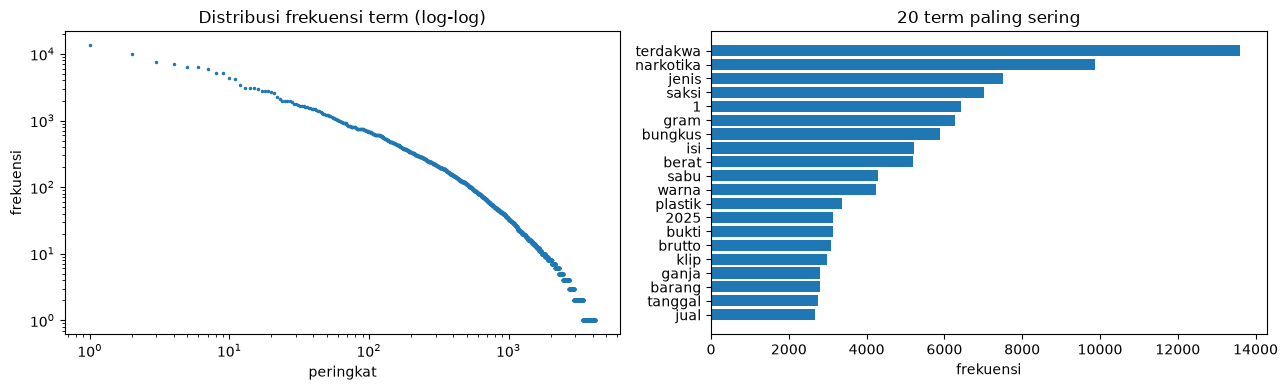

In [35]:
# Hukum Zipf dan istilah paling sering
freq = Counter(t for d in DOC_IDS for t in tokens[d])
ranked = freq.most_common()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].loglog(range(1, len(ranked) + 1), [c for _, c in ranked], marker=".", linestyle="none", markersize=3)
axes[0].set(title="Distribusi frekuensi term (log-log)", xlabel="peringkat", ylabel="frekuensi")
top = ranked[:20][::-1]
axes[1].barh([t for t, _ in top], [c for _, c in top])
axes[1].set(title="20 term paling sering", xlabel="frekuensi")
plt.tight_layout()
plt.show()

In [36]:
# Penyimpanan index dan estimasi kompresi gap + variable-byte encoding
def vbyte_len(n):
    return max(1, math.ceil(n.bit_length() / 7))


raw_bytes = vb_bytes = 0
for t, postings in index.items():
    prev_doc = -1
    for d in sorted(postings, key=DOC_IDS.index):
        di = DOC_IDS.index(d)
        raw_bytes += 4 + 4 * len(postings[d])
        vb_bytes += vbyte_len(di - prev_doc) + sum(vbyte_len(g) for g in
                                                 [postings[d][0] + 1] + [b - a for a, b in zip(postings[d], postings[d][1:])])
        prev_doc = di

with gzip.open(INDEX_DIR / "positional_index.json.gz", "wt", encoding="utf-8") as f:
    json.dump({"docs": DOC_IDS, "index": index}, f)
meta.to_csv(INDEX_DIR / "doc_metadata.csv", encoding="utf-8-sig")
print(f"Posting mentah (int 32-bit)  : {raw_bytes / 1024:,.0f} KB")
print(f"Gap + variable-byte encoding : {vb_bytes / 1024:,.0f} KB ({vb_bytes / raw_bytes:.0%} dari ukuran mentah)")
print(f"Tersimpan: index/positional_index.json.gz ({(INDEX_DIR / 'positional_index.json.gz').stat().st_size / 1024:,.0f} KB), index/doc_metadata.csv")

Posting mentah (int 32-bit)  : 1,486 KB
Gap + variable-byte encoding : 498 KB (34% dari ukuran mentah)
Tersimpan: index/positional_index.json.gz (876 KB), index/doc_metadata.csv


### Pembobotan dan Model Pencarian

Empat model dibandingkan, dari pencocokan himpunan hingga pembobotan per zona:

| Model | Rumus |
|---|---|
| Boolean | himpunan dokumen yang memuat semua term query (AND), mendukung frasa `"..."` dan `-term` (NOT) |
| TF-IDF (VSM) | $w_{t,d} = (1 + \log tf_{t,d}) \cdot \log \frac{N}{df_t}$, skor = kosinus antara vektor query dan dokumen |
| BM25 | $\sum_t \text{idf}_t \cdot \frac{tf_{t,d}(k_1+1)}{tf_{t,d} + k_1(1-b+b\frac{|d|}{avgdl})}$, $\text{idf}_t = \log\left(1 + \frac{N-df_t+0.5}{df_t+0.5}\right)$, $k_1 = 1.2$, $b = 0.75$ |
| BM25F (zona) | $\tilde{tf}_{t,d} = \sum_z w_z \frac{tf_{t,d,z}}{1-b+b\frac{|d_z|}{avg_z}}$, skor $= \sum_t \text{idf}_t \frac{\tilde{tf}_{t,d}}{k_1 + \tilde{tf}_{t,d}}$ |

TF-IDF memberi bobot berdasarkan frekuensi dan kelangkaan term. BM25 menambahkan saturasi tf (kemunculan ke-20 tidak bernilai 20 kali kemunculan pertama) dan normalisasi panjang dokumen, yang penting karena panjang putusan berkisar 18 sampai 165 halaman. BM25F menghitung tf per zona sebelum digabung, sehingga kemunculan di amar dapat dibobot lebih tinggi.

Bobot zona BM25F ditetapkan sebelum evaluasi berdasarkan struktur putusan: `amar` 3,0 (yang diputus), `tuntutan` 1,0, `pertimbangan` 1,0, `kepala` 0,5, dan `dakwaan` 0,5 (memuat pasal alternatif yang belum tentu terbukti).

In [37]:
K1, B = 1.2, 0.75
ZONE_WEIGHT = {"amar": 3.0, "tuntutan": 1.0, "pertimbangan": 1.0, "kepala": 0.5, "dakwaan": 0.5}
idf_bm25 = lambda t: math.log(1 + (N - df.get(t, 0) + 0.5) / (df.get(t, 0) + 0.5))
idf_vsm = lambda t: math.log(N / df[t]) if df.get(t) else 0.0

doc_norm = {d: 0.0 for d in DOC_IDS}
for t, postings in index.items():
    for d, pos in postings.items():
        doc_norm[d] += ((1 + math.log(len(pos))) * idf_vsm(t)) ** 2
doc_norm = {d: math.sqrt(v) or 1.0 for d, v in doc_norm.items()}


def parse_query(q):
    phrases = [preprocess(p) for p in re.findall(r'"([^"]+)"', q)]
    rest = re.sub(r'"[^"]+"', " ", q)
    excluded = {s for w in re.findall(r"-(\S+)", rest) for s in preprocess(w)}
    terms = preprocess(re.sub(r"-\S+", " ", rest)) + [t for p in phrases for t in p]
    return terms, [p for p in phrases if p], excluded


def phrase_docs(phrase):
    if not phrase or any(t not in index for t in phrase):
        return set()
    hits = set()
    for d in set.intersection(*(set(index[t]) for t in phrase)):
        starts = set(index[phrase[0]][d])
        for k, t in enumerate(phrase[1:], 1):
            starts &= {p - k for p in index[t][d]}
        if starts:
            hits.add(d)
    return hits


def boolean(q):
    terms, phrases, excluded = parse_query(q)
    result = set(DOC_IDS)
    for t in terms:
        result &= set(index.get(t, {}))
    for p in phrases:
        result &= phrase_docs(p)
    for t in excluded:
        result -= set(index.get(t, {}))
    return sorted(result, key=lambda d: int(d.split("/")[0]))


def tfidf(q):
    terms, _, _ = parse_query(q)
    qtf = Counter(terms)
    qw = {t: (1 + math.log(c)) * idf_vsm(t) for t, c in qtf.items()}
    qnorm = math.sqrt(sum(w * w for w in qw.values())) or 1.0
    scores = defaultdict(float)
    for t, w in qw.items():
        for d, pos in index.get(t, {}).items():
            scores[d] += w * (1 + math.log(len(pos))) * idf_vsm(t)
    return {d: s / (qnorm * doc_norm[d]) for d, s in scores.items()}


def bm25(q):
    terms, _, _ = parse_query(q)
    scores = defaultdict(float)
    for t in set(terms):
        for d, pos in index.get(t, {}).items():
            tf = len(pos)
            scores[d] += idf_bm25(t) * tf * (K1 + 1) / (tf + K1 * (1 - B + B * doc_len[d] / avgdl))
    return dict(scores)


def bm25f(q):
    terms, _, _ = parse_query(q)
    scores = defaultdict(float)
    for t in set(terms):
        pseudo = defaultdict(float)
        for z, w in ZONE_WEIGHT.items():
            for d, tf in zone_index[z].get(t, {}).items():
                pseudo[d] += w * tf / (1 - B + B * zone_len[z][d] / zone_avg[z])
        for d, tf in pseudo.items():
            scores[d] += idf_bm25(t) * tf / (K1 + tf)
    return dict(scores)


def rank(scores, k=None, required=None, filters=None):
    docs_ = [d for d in scores if (required is None or d in required)]
    if filters:
        docs_ = [d for d in docs_ if all(str(v).lower() in str(meta.loc[d, c]).lower() for c, v in filters.items())]
    ordered = sorted(docs_, key=lambda d: (-scores[d], int(d.split("/")[0])))
    return ordered[:k] if k else ordered


MODELS = {"TF-IDF": tfidf, "BM25": bm25, "BM25F": bm25f}
print("Model siap:", ", ".join(["Boolean", *MODELS]))

Model siap: Boolean, TF-IDF, BM25, BM25F


### Demo Pencarian

`search()` menampilkan peringkat, skor, jenis narkotika, vonis, dan cuplikan amar di sekitar term query. Model bawaannya BM25F.

- Frasa ditulis dalam tanda kutip, misalnya `"tembakau sintetis"`, dan term yang dikecualikan diberi awalan `-`. Bila query memuat frasa atau pengecualian, hanya dokumen yang lolos pencocokan Boolean yang diperingkat.
- `filters` membatasi hasil berdasarkan metadata, misalnya `filters={"Jenis Narkotika": "Ganja"}`.

Contoh terakhir menunjukkan Boolean retrieval: hasilnya berupa himpunan nomor putusan tanpa urutan relevansi.

In [38]:
def snippet(d, q, width=110):
    """Short excerpt from the amar (fallback: full text) around the first query term."""
    terms = set(parse_query(q)[0])
    for source in (docs[d]["zones"]["amar"], docs[d]["text"]):
        words = source.split()
        for i, w in enumerate(words):
            if terms & set(preprocess(w)):
                left = " ".join(words[max(0, i - 8):i])
                right = " ".join(words[i + 1:i + 14])
                return f"... {left} [{w}] {right} ..."[: width + 40]
    return ""


def search(q, model="BM25F", k=5, filters=None):
    terms, phrases, excluded = parse_query(q)
    required = boolean(q) if (phrases or excluded) else None
    scores = MODELS[model](q)
    rows = [{"rank": i, "No Putusan": d, "skor": round(scores[d], 4), "jenis": meta.loc[d, "Jenis Narkotika"],
             "vonis (bln)": meta.loc[d, "Vonis (bulan)"], "cuplikan": snippet(d, q)}
            for i, d in enumerate(rank(scores, k, required, filters), 1)]
    print(f"Query: {q!r} | model {model} | term: {terms}" + (f" | filter {filters}" if filters else ""))
    return pd.DataFrame(rows)


search("permufakatan jahat perantara jual beli sabu")

Query: 'permufakatan jahat perantara jual beli sabu' | model BM25F | term: ['mufakat', 'jahat', 'perantara', 'jual', 'beli', 'sabu']


,rank,No Putusan,skor,jenis,vonis (bln),cuplikan
0,1,281/Pid.Sus/2025/PN Bks,1.2309,Sabu (metamfetamina),96.0,"... sah dan meyakinan bersalah melakukan tindak pidana "" [Pemufakatan] Jahat Tanpa hak..."
1,2,282/Pid.Sus/2025/PN Bks,1.2224,Sabu (metamfetamina),96.0,"... sah dan meyakinan bersalah melakukan tindak pidana "" [Pemufakatan] Jahat Tanpa hak..."
2,3,127/Pid.Sus/2025/PN Bks,1.2083,Sabu (metamfetamina),84.0,"... sah dan meyakinkan bersalah melakukan tindak pidana ""melakukan [permufakatan] jaha..."
3,4,126/Pid.Sus/2025/PN Bks,1.2082,Sabu (metamfetamina),84.0,"... sah dan meyakinkan bersalah melakukan tindak pidana ""melakukan [permufakatan] jaha..."
4,5,125/Pid.Sus/2025/PN Bks,1.2055,Sabu (metamfetamina),84.0,"... sah dan meyakinkan bersalah melakukan tindak pidana ""melakukan [permufakatan] jaha..."


In [39]:
search('"tembakau sintetis" timbangan digital', model="BM25F")

Query: '"tembakau sintetis" timbangan digital' | model BM25F | term: ['timbang', 'digital', 'tembakau', 'sintetis']


,rank,No Putusan,skor,jenis,vonis (bln),cuplikan
0,1,243/Pid.Sus/2025/PN Bks,2.6749,Tembakau sintetis,84.0,... terbungkus lakban cokelat berisikan Narkotika Gol I jenis [tembakau] sintetis; 1.5...
1,2,374/Pid.Sus/2025/PN Bks,2.6629,Tembakau sintetis,90.0,... diduga berisikan Narkotika golongan I bukan tanaman jenis [Tembakau] Sintetis deng...
2,3,261/Pid.Sus/2025/PN Bks,2.6512,Tembakau sintetis,84.0,... Diduga Berisikan Narkotika Golongan I Bukan Tanaman Jenis [Tembakau] Sintetis Deng...


In [40]:
search("pidana penjara narkotika", filters={"Jenis Narkotika": "Ganja"}, k=5)

Query: 'pidana penjara narkotika' | model BM25F | term: ['pidana', 'penjara', 'narkotika'] | filter {'Jenis Narkotika': 'Ganja'}


,rank,No Putusan,skor,jenis,vonis (bln),cuplikan
0,1,283/Pid.Sus/2025/PN Bks,0.0868,Ganja,84.0,"... terbukti secara sah dan meyakinkan bersalah melakukan tindak [pidana] ""yang tanpa ..."
1,2,128/Pid.Sus/2025/PN Bks,0.0867,"Sabu (metamfetamina), Ganja",96.0,"... terbukti secara sah dan meyakinkan bersalah melakukan tindak [pidana] ""Tanpa hak d..."
2,3,208/Pid.Sus/2025/PN Bks,0.0863,Ganja,72.0,"... terbukti secara sah dan meyakinan bersalah melakukan tindak [pidana] ""pidana permu..."
3,4,398/Pid.Sus/2025/PN Bks,0.0863,"Sabu (metamfetamina), Ganja",108.0,"... terbukti secara sah dan meyakinkan bersalah melakukan tindak [pidana] ""Tanpa hak d..."
4,5,131/Pid.Sus/2025/PN Bks,0.0860,Ganja,96.0,"... terbukti secara sah dan meyakinkan bersalah melakukan tindak [pidana] ""Tanpa Hak a..."


In [41]:
print("Boolean  ganja -sabu   :", [d.split("/")[0] for d in boolean("ganja -sabu")])
print('Boolean "golongan I" ekstasi:', [d.split("/")[0] for d in boolean('"golongan I" ekstasi')])
print('Boolean "pasal 132" :', len(boolean('"pasal 132"')), "dokumen")

Boolean  ganja -sabu   : ['131', '283', '284', '288', '343', '344']
Boolean "golongan I" ekstasi: ['107', '412']
Boolean "pasal 132" : 25 dokumen


### Evaluasi

Relevance judgment (qrels) dibuat dari `Overview.xlsx`, yaitu metadata halaman Direktori Putusan. Sumber ini terpisah dari teks PDF yang diindeks, sehingga evaluasi tidak bersifat sirkular. Kebutuhan informasi dan kriteria relevansinya:

| ID | Query | Dokumen relevan bila |
|---|---|---|
| Q1 | barang bukti ganja | barang bukti memuat ganja |
| Q2 | tembakau sintetis | barang bukti memuat tembakau sintetis / MDMB-BUTINACA |
| Q3 | pil ekstasi | barang bukti memuat ekstasi atau tablet |
| Q4 | permufakatan jahat | terdakwa **terbukti** melakukan permufakatan jahat (diktum pertama amar) |
| Q5 | perantara dalam jual beli narkotika | terdakwa **terbukti** menjadi perantara jual beli |
| Q6 | memiliki menyimpan menguasai narkotika | terdakwa **terbukti** memiliki, menyimpan, atau menguasai |
| Q7 | narkotika golongan I dalam bentuk tanaman | tindak pidana yang terbukti menyangkut narkotika bentuk tanaman |
| Q8 | para terdakwa | perkara dengan lebih dari satu terdakwa |
| Q9 | barang bukti dirampas untuk negara | amar memuat "dirampas untuk negara" |
| Q10 | uang hasil penjualan narkotika | barang bukti memuat uang |

Q4 sampai Q7 sengaja sulit: istilah yang sama juga muncul di dakwaan dan tuntutan pada perkara yang **tidak** membuktikannya.

Metrik yang dipakai, dengan relevansi biner:

| Metrik | Arti |
|---|---|
| P@5, P@10 | proporsi dokumen relevan di 5 atau 10 hasil teratas |
| R@10 | proporsi seluruh dokumen relevan yang muncul di 10 hasil teratas |
| MAP | rata-rata Average Precision atas 10 query. AP merata-ratakan presisi pada setiap posisi dokumen relevan, sehingga dokumen relevan di peringkat bawah menurunkan nilai |
| nDCG@10 | gain dokumen relevan didiskon menurut posisinya, lalu dibagi nilai peringkat ideal. Nilai 1,0 berarti semua dokumen relevan berada paling atas |
| MRR | rata-rata 1/peringkat dokumen relevan pertama |

Semua metrik bernilai 0 sampai 1, makin tinggi makin baik. Query dengan kurang dari 5 dokumen relevan tidak dapat mencapai P@5 = 1.

In [42]:
web = overview.set_index("No Putusan")
bb = web["Barang Bukti"].str.lower()
amar = web["Amar Putusan"].str.lower()
amar1 = amar.str.split(r"menjatuhkan", n=1, regex=True).str[0]  # diktum pertama: tindak pidana yang terbukti

QUERIES = {
    "Q1": ("barang bukti ganja", bb.str.contains(r"\bganja\b")),
    "Q2": ("tembakau sintetis", bb.str.contains(r"tembakau sintetis|mdmb|butinaca")),
    "Q3": ("pil ekstasi", bb.str.contains(r"ekstasi|tablet")),
    "Q4": ("permufakatan jahat", amar1.str.contains(r"permufakatan|pemufakatan")),
    "Q5": ("perantara dalam jual beli narkotika", amar1.str.contains(r"perantara")),
    "Q6": ("memiliki menyimpan menguasai narkotika", amar1.str.contains(r"menyimpan|menguasai|memiliki")),
    "Q7": ("narkotika golongan I dalam bentuk tanaman", amar1.str.contains(r"(?<!bukan )tanaman")),
    "Q8": ("para terdakwa", amar.str.contains(r"para terdakwa|terdakwa ii\b")),
    "Q9": ("barang bukti dirampas untuk negara", amar.str.contains(r"dirampas untuk negara")),
    "Q10": ("uang hasil penjualan narkotika", bb.str.contains(r"\buang\b")),
}
QRELS = {qid: set(mask[mask].index) & set(DOC_IDS) for qid, (_, mask) in QUERIES.items()}
pd.DataFrame([(qid, q, len(QRELS[qid])) for qid, (q, _) in QUERIES.items()], columns=["ID", "Query", "Jumlah relevan"])

,ID,Query,Jumlah relevan
0,Q1,barang bukti ganja,12
1,Q2,tembakau sintetis,11
2,Q3,pil ekstasi,2
3,Q4,permufakatan jahat,21
4,Q5,perantara dalam jual beli narkotika,28
5,Q6,memiliki menyimpan menguasai narkotika,1
6,Q7,narkotika golongan I dalam bentuk tanaman,4
7,Q8,para terdakwa,4
8,Q9,barang bukti dirampas untuk negara,11
9,Q10,uang hasil penjualan narkotika,4


In [43]:
def precision_at(r, rel, k):
    return sum(d in rel for d in r[:k]) / k


def recall_at(r, rel, k):
    return sum(d in rel for d in r[:k]) / len(rel)


def average_precision(r, rel):
    hits, total = 0, 0.0
    for i, d in enumerate(r, 1):
        if d in rel:
            hits += 1
            total += hits / i
    return total / len(rel)


def ndcg_at(r, rel, k=10):
    dcg = sum(1 / math.log2(i + 1) for i, d in enumerate(r[:k], 1) if d in rel)
    idcg = sum(1 / math.log2(i + 1) for i in range(1, min(len(rel), k) + 1))
    return dcg / idcg


def reciprocal_rank(r, rel):
    return next((1 / i for i, d in enumerate(r, 1) if d in rel), 0.0)


def evaluate(model_fn):
    rows = []
    for qid, (q, _) in QUERIES.items():
        r, rel = rank(model_fn(q)), QRELS[qid]
        rows.append({"ID": qid, "P@5": precision_at(r, rel, 5), "P@10": precision_at(r, rel, 10),
                     "R@10": recall_at(r, rel, 10), "AP": average_precision(r, rel),
                     "nDCG@10": ndcg_at(r, rel), "RR": reciprocal_rank(r, rel)})
    return pd.DataFrame(rows).set_index("ID")


per_query = {name: evaluate(fn) for name, fn in MODELS.items()}
summary = pd.DataFrame({name: res.mean() for name, res in per_query.items()}).T
summary = summary.rename(columns={"AP": "MAP", "RR": "MRR"})
summary.round(3)

,P@5,P@10,R@10,MAP,nDCG@10,MRR
TF-IDF,0.54,0.52,0.550,0.624,0.646,0.735
BM25,0.60,0.54,0.599,0.700,0.703,0.748
BM25F,0.64,0.59,0.741,0.722,0.769,0.749


Tabel di atas adalah rata-rata setiap metrik atas 10 query. Tabel berikutnya merinci Average Precision per query, sehingga terlihat query mana yang membedakan model, terutama Q4 sampai Q7.

Boolean retrieval dinilai terpisah sebagai himpunan dengan precision, recall, dan F1, karena tidak menghasilkan peringkat.

In [44]:
# Per query: Average Precision tiap model
ap_table = pd.DataFrame({name: res["AP"] for name, res in per_query.items()})
ap_table.insert(0, "Query", [QUERIES[q][0] for q in ap_table.index])
ap_table.insert(1, "Relevan", [len(QRELS[q]) for q in ap_table.index])
ap_table.round(3)

,Query,Relevan,TF-IDF,BM25,BM25F
ID,,,,,
Q1,barang bukti ganja,12,1.000,1.000,1.000
Q2,tembakau sintetis,11,0.909,0.909,0.909
Q3,pil ekstasi,2,1.000,1.000,1.000
Q4,permufakatan jahat,21,0.973,0.952,0.996
Q5,perantara dalam jual beli narkotika,28,0.621,0.746,0.820
Q6,memiliki menyimpan menguasai narkotika,1,0.029,0.091,0.125
Q7,narkotika golongan I dalam bentuk tanaman,4,0.207,0.166,0.165
Q8,para terdakwa,4,0.149,1.000,1.000
Q9,barang bukti dirampas untuk negara,11,0.958,0.954,0.986


In [45]:
# Boolean retrieval dinilai sebagai himpunan (tanpa peringkat)
bool_rows = []
for qid, (q, _) in QUERIES.items():
    got, rel = set(boolean(q)), QRELS[qid]
    p = len(got & rel) / len(got) if got else 0.0
    r_ = len(got & rel) / len(rel)
    bool_rows.append({"ID": qid, "Dikembalikan": len(got), "Precision": p, "Recall": r_,
                      "F1": 2 * p * r_ / (p + r_) if p + r_ else 0.0})
pd.DataFrame(bool_rows).set_index("ID").round(3)

,Dikembalikan,Precision,Recall,F1
ID,,,,
Q1,16,0.750,1.000,0.857
Q2,12,0.833,0.909,0.870
Q3,2,1.000,1.000,1.000
Q4,27,0.778,1.000,0.875
Q5,49,0.571,1.000,0.727
Q6,49,0.020,1.000,0.040
Q7,44,0.091,1.000,0.167
Q8,49,0.082,1.000,0.151
Q9,19,0.579,1.000,0.733


### Ablasi Preprocessing

Pengaruh setiap tahap preprocessing terhadap BM25: index dibangun ulang tanpa stemming dan tanpa stopword removal, lalu dievaluasi dengan qrels yang sama. Bila MAP turun saat suatu tahap dihapus, tahap itu membantu. Bila MAP naik, tahap itu justru merugikan pada korpus ini.

Grafik setelah tabel ablasi membandingkan TF-IDF, BM25, dan BM25F pada P@5, R@10, MAP, dan nDCG@10.

In [46]:
def bm25_variant(**kwargs):
    toks = {d: preprocess(docs[d]["text"], **kwargs) for d in DOC_IDS}
    idx = defaultdict(lambda: defaultdict(int))
    for d in DOC_IDS:
        for t in toks[d]:
            idx[t][d] += 1
    lens = {d: len(toks[d]) for d in DOC_IDS}
    avg = sum(lens.values()) / N

    def fn(q):
        scores = defaultdict(float)
        for t in set(preprocess(q, **kwargs)):
            postings = idx.get(t, {})
            idf = math.log(1 + (N - len(postings) + 0.5) / (len(postings) + 0.5))
            for d, tf in postings.items():
                scores[d] += idf * tf * (K1 + 1) / (tf + K1 * (1 - B + B * lens[d] / avg))
        return dict(scores)
    return fn


ablation = {
    "BM25 lengkap": per_query["BM25"].mean(),
    "BM25 tanpa stemming": evaluate(bm25_variant(use_stemming=False)).mean(),
    "BM25 tanpa stopword removal": evaluate(bm25_variant(use_stopwords=False)).mean(),
    "BM25F (zona)": per_query["BM25F"].mean(),
}
ablation = pd.DataFrame(ablation).T.rename(columns={"AP": "MAP", "RR": "MRR"})
ablation.round(3)

,P@5,P@10,R@10,MAP,nDCG@10,MRR
BM25 lengkap,0.60,0.54,0.599,0.700,0.703,0.748
BM25 tanpa stemming,0.64,0.56,0.724,0.711,0.749,0.756
BM25 tanpa stopword removal,0.60,0.55,0.699,0.701,0.732,0.747
BM25F (zona),0.64,0.59,0.741,0.722,0.769,0.749


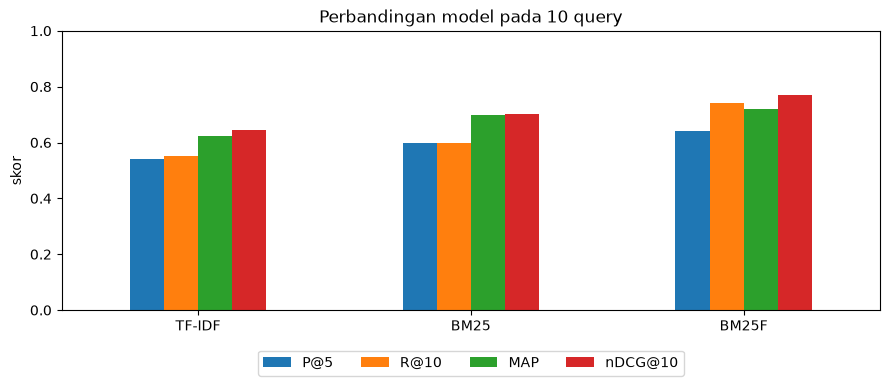

In [47]:
ax = summary[["P@5", "R@10", "MAP", "nDCG@10"]].plot.bar(figsize=(9, 4), rot=0)
ax.set(title="Perbandingan model pada 10 query", ylabel="skor", ylim=(0, 1))
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()

### Kesimpulan

Ringkasan berikut dihitung langsung dari hasil evaluasi di atas, sehingga tetap sesuai bila notebook dijalankan ulang.

In [48]:
best = summary.idxmax()
print("Model terbaik per metrik:")
for metric, model in best.items():
    print(f"  {metric:8s}: {model} ({summary.loc[model, metric]:.3f})")

gain = summary.loc["BM25F"] - summary.loc["BM25"]
print("\nBM25F dibanding BM25:", ", ".join(f"{m} {v:+.3f}" for m, v in gain.items()))
hard = ["Q4", "Q5", "Q6", "Q7"]
print("MAP pada query 'apa yang terbukti' (Q4-Q7):",
      ", ".join(f"{m} {per_query[m].loc[hard, 'AP'].mean():.3f}" for m in MODELS))

base = ablation.loc["BM25 lengkap", "MAP"]
print("\nAblasi (selisih MAP terhadap BM25 lengkap):")
for name in ["BM25 tanpa stemming", "BM25 tanpa stopword removal"]:
    print(f"  {name:28s}: {ablation.loc[name, 'MAP'] - base:+.3f}")

Model terbaik per metrik:
  P@5     : BM25F (0.640)
  P@10    : BM25F (0.590)
  R@10    : BM25F (0.741)
  MAP     : BM25F (0.722)
  nDCG@10 : BM25F (0.769)
  MRR     : BM25F (0.749)

BM25F dibanding BM25: P@5 +0.040, P@10 +0.050, R@10 +0.142, MAP +0.022, nDCG@10 +0.066, MRR +0.000
MAP pada query 'apa yang terbukti' (Q4-Q7): TF-IDF 0.458, BM25 0.489, BM25F 0.526

Ablasi (selisih MAP terhadap BM25 lengkap):
  BM25 tanpa stemming         : +0.011
  BM25 tanpa stopword removal : +0.001


Pembahasan:

- **Preprocessing domain hukum.** Normalisasi ejaan narkotika, nomor pasal dan golongan yang dipertahankan (`114`, `golongan_i`), stopword formula putusan, dan perlindungan istilah dari stemming berlebih (`terdakwa`, `perantara`, `penuntut`) membuat term sesuai dengan cara orang mencari putusan.
- **Index posisional** mendukung pencarian frasa seperti `"permufakatan jahat"` dan `"pasal 132"`, dan ukurannya dapat ditekan dengan gap dan variable-byte encoding.
- **BM25F berbasis zona** memanfaatkan struktur putusan. Istilah di amar (yang diputus) diberi bobot lebih tinggi daripada di dakwaan (yang didakwakan), sehingga perkara yang benar-benar membuktikan suatu perbuatan naik ke peringkat atas.
- **Boolean retrieval** memiliki recall tinggi tetapi presisi rendah pada korpus yang homogen. Hampir semua putusan narkotika memuat istilah seperti "perantara", "jual", dan "beli" di dakwaan, sehingga pemeringkatan berbobot diperlukan.
- **Ablasi.** Pada korpus kecil yang sangat homogen, stemming dan stopword removal tidak selalu menaikkan kualitas. Stemming menyatukan bentuk kata yang bermakna hukum berbeda (misalnya `menyimpan` dan `simpanan`). Karena itu daftar kata yang dilindungi dan pengecualian stopword hukum menjadi bagian penting dari pipeline.
- **Batasan evaluasi.** Qrels berasal dari metadata situs yang terpisah dari teks terindeks, tetapi sampelnya kecil (10 query, 50 dokumen). Selisih antarmodel di bawah sekitar 0,05 perlu dibaca dengan hati-hati.

## Unduh Keluaran

Di Colab, sel berikut mengunduh `hasil_uts_ir.zip` yang berisi seluruh folder keluaran:

| Folder | Isi |
|---|---|
| `crawl/pdf_files/`, `crawl/txt_files/` | PDF putusan dan teks bersihnya |
| `crawl/hasil_ekstraksi_putusan.csv` | hasil ekstraksi Soal 3 |
| `crawl/crawl_log.csv`, `crawl/crawl_http.jsonl` | status dan sumber setiap PDF, log setiap permintaan HTTP |
| `index/positional_index.json.gz`, `index/doc_metadata.csv` | index posisional dan metadata Soal 4 |

Untuk pengumpulan Soal 3, unggah folder PDF dan TXT ke Drive, lalu bagikan tautannya bersama tautan Colab.

In [49]:
if IN_COLAB:
    from google.colab import files
    bundle = WORK.parent / "hasil_uts_ir.zip"
    with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
        for path in sorted(WORK.rglob("*")):
            if path.is_file():
                z.write(path, path.relative_to(WORK).as_posix())
    files.download(str(bundle))
else:
    print("Keluaran tersimpan di outputs/ (atau UTS_IR_OUTPUT bila diatur).")

Keluaran tersimpan di outputs/ (atau UTS_IR_OUTPUT bila diatur).
